# Why random nudges stopped changing the algorithm: plan-noise unit × seeds crosswalk (demo)

**Model and setup.** Qwen/Qwen3-8B (revision `b968826d`, bf16 HF transformers, thinking off) nearly always writes one *default* algorithm per programming task: union-find for connected components (**T10**), Dijkstra for weighted shortest paths (**T2**), BFS for grid paths, a full sort for the k-th smallest, a hash map for two-sum.

**Plan noise (PN)** tries to change the algorithm the model picks. It pushes a fresh random direction `u` (one per sample) into the residual stream at the task-specification positions of decoder blocks 12–23, during the prompt prefill only. The edit is *displacement-targeted*:

$$h \leftarrow h + \big(\alpha\, n[l,p] - (h - h_{\text{twin}})\cdot u\big)\, u ,$$

so at every edited cell the displacement from the clean *twin* run along `u` is exactly α·n[l,p]. The array n[l,p] is the **dose unit**.

**The puzzle.** Iteration 4's plan noise moved T10 off union-find on 25 of 50 programs; iteration 5's moved it on 1 of 50. The two designs differed in

- the **dose unit**: `U_abs` = the ban's own per-block, per-position displacement norm, vs `U_bf` = ‖h_twin[l,p]‖ · r_Q(l);
- the **direction seeds**: `S4` (exp29) vs `S5` (exp27).

This experiment crosses the two on shared common-random-number (CRN) slots: one prompt and one uniform stream per slot, shared by every arm.

| design | dose unit | seeds |
|---|---|---|
| D1 | U_abs | S4 |
| D2 | U_abs | S5 |
| D3 | U_bf | S4 |
| D4 | U_bf | S5 |
| D5 | U_bf* = U_bf's profile at U_abs's per-block energy | S4 |
| P_top / P_rest / P_shuf | U_abs on its top-quartile cells only / on the other cells / with spec positions permuted | S4 |

**Answer (committed decision rule): UNIT.** On T10 at α 2 the shares of correct, named off-default programs are D1 0.50, D2 0.52, D3 0.10, D4 0.02. The unit effect is +0.45 [0.35, 0.55] and the seed effect +0.03 [−0.07, 0.14]. The pushes act where bans write: P_top 0.58 vs P_rest 0.30, and position-shuffling drops D1's 0.50 to 0.08.

**What this notebook runs.** The original pipeline (`method.py`) decodes 2,880 programs with the 8B model on a 24 GB GPU (about 0.66 GPU-hours), which does not fit here. The notebook keeps the original code and replays everything downstream of generation on the logged outputs of **100 CRN slots** (`mini_demo_data.json`: T10 and T2 × templates W1–W5 × k 0–9, with every arm generated on each slot):

1. the dose units and per-sample directions (`src/k_units.py`), rebuilt from the logged activation norms and checked against the unit dump;
2. the original TARGET edit hooks (`hooks4.make_edits_v4`, `gen_k.make_edits_masked`), run on CPU tensors with stand-in twin states;
3. the committed analysis (`src/analysis_k.py`): anchors, the unit × seeds 2×2, the D5 split, mediation, the profile split, the D* rule and the E1 dose sweep;
4. the exploratory E2 geometry on the logged block-35 displacement vectors (`src/geometry_k.py`);
5. the figures in activation coordinates (`src/figures_k.py`), and a table comparing every re-derived number with the published one.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, scipy, scikit-learn, statsmodels, matplotlib, torch — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'statsmodels==0.14.6',
         'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# method.py and src/k_cfg.py
import hashlib
import json
import math
import os
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Callable, Iterable

# src/analysis_k.py, src/k_units.py, src/gen_k.py (edit hooks), src/geometry_k.py, src/figures_k.py
import itertools
from collections import Counter, defaultdict

import matplotlib
import matplotlib.pyplot as plt  # (the scripts call matplotlib.use("Agg"); dropped here so figures render inline)
import numpy as np
import torch
from loguru import logger

# notebook additions: decode the logged fp16 vectors shipped in the mini data, tabulate the results
import base64
import zlib

import pandas as pd

# method.py's logging setup (stdout sink; the logs/method.log file sink is dropped in the notebook)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}");

# notebook: print library warnings as "Category: message", without the environment-specific source path
import warnings
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-7/experiment-36/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

_ex = data["datasets"][0]["examples"]
print(data["metadata"]["artifact"])
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(_ex)} CRN slots, "
      f"{sum(len(e['raw']) for e in _ex)} programs, {sum(len(e['disp_R35']) for e in _ex)} block-35 vectors")
print("one slot:", {k: v for k, v in _ex[0].items() if k.startswith(("output", "predict_D1", "predict_D4", "metadata"))})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_8O5eaNc5gxJs (iteration 7, step K: why random nudges stopped changing the algorithm)
dataset 'k_slots_T10_T2': 100 CRN slots, 1600 programs, 700 block-35 vectors
one slot: {'output': 'union_find|True', 'predict_D1_a1': 'union_find|True', 'predict_D1_a2': 'union_find|True', 'predict_D4_a1': 'union_find|True', 'predict_D4_a2': 'union_find|True', 'metadata_task': 'T10', 'metadata_template': 'W1', 'metadata_k': 0, 'metadata_uniform_seed': 4760974216549214469}


## Configuration

Every knob that changes the amount of work is set here. Each line says which value the original run used.

- `K_USE` selects the CRN sample ids k kept per (task, template). The mini data holds k 0–9, which is 50 slots per task: exactly the committed T10 slots. T2's committed α-2 slots were k 0–19 (N 100), so T2 α-2 numbers here correspond to the published `T2|a2|Y|k0-9` sensitivity table.
- `N_BOOT` is the number of slot-cluster bootstrap replicates behind every 95% CI.
- `N_FLIP` is the number of Monte-Carlo sign flips used when a contrast has more than 20 non-zero slot contributions (up to 20 are enumerated exactly).
- `EDIT_DEMO` is the slot whose TARGET edit is replayed on CPU tensors.
- `GEOMETRY_TASKS` lists the tasks whose block-35 displacement vectors ship in the mini data (T10; the original E2/F5/F7 also drew T2).

In [5]:
# ---- tunable parameters (demo values; the original run's values are in the comments) ----
K_USE = list(range(10))      # CRN sample ids k per (task, template); original: k 0-9 (T2 alpha 2: k 0-19); mini data: k 0-9
N_BOOT = 2000                # slot-cluster bootstrap replicates per 95% CI; original: 2000
N_FLIP = 100_000             # Monte-Carlo sign flips (> 20 non-zero slots); original: 100_000
BOOT_SEED = 20261022         # bootstrap / sign-flip seed; original: 20261022
EDIT_DEMO = {"task": "T10", "template": "W1", "k": 0, "alpha": 2.0}   # slot replayed by the CPU edit demo
GEOMETRY_TASKS = ("T10",)    # tasks with block-35 vectors in the mini data; original E2/F5/F7: ("T10", "T2")

## 1. The pipeline (`method.py`)

`method.py` is the entry point: `uv run method.py <step> [<step> ...]` or `uv run method.py all`. Every step is a module in `src/` that runs in its own process; the GPU steps load one 8B model at a time.

Every step is resumable:

- Generation and labels are keyed by `<task>|<template>|<arm>|<sample_id>`.
- `commit1` / `commit2` append to a sha256 hash chain only when their file is missing (`SKIP_IF_EXISTS`).
- `label` starts a background worker that labels every generated program (runtime tests, AST, and a judge only on disagreement).

The cell below copies the step table verbatim and marks what each step needs. `main()` would launch each module as a subprocess. Those files and the GPU are not available here, so the notebook calls the CPU code of the replayed steps in-process instead, on the rows that the GPU steps logged.

In [6]:
"""Step K of iteration 7: why random nudges stopped changing the algorithm.   (method.py docstring)

  setup      copy and sha256-verify every earlier-artifact input into inputs/ and vendor/   (src/setup_inputs.py)
  gates      CPU gates G1-G5 -> results/cpu_gates.json                                      (src/s3_prices.py g5, src/cpu_gates.py)
  label      start the label worker in the background (follows data/raw/*.jsonl)          (src/label_k.py)
  gpu0       hardware record, memory probe, GPU unit tests U1-U6, S0 twins                 (src/gen_k.py tests s0)
  commit1    COMMIT #1: design table, units, seeds, rules, predictions, analysis code hash (src/make_commits.py)
  gpu1       S1 2x2 (anchors first) + D5 + S2 profiles                                     (src/gen_k.py s1 d5 s2)
  commit2    COMMIT #2: D* rule applied to the labelled S1 rows, S3 predictions and rules  (src/make_commits.py)
  gpu2       S3 plan-noise cells at D* on T03, T05, T1                                      (src/gen_k.py s3pn)
  knobs      base-model intents, exp27 knob rows relabelled, knob check, reruns            (src/knobs_k.py)
  units      dose units in activation coordinates for the figures                          (src/dump_units.py)
  e1         exploratory dose sweep of the ban-free unit (committed before its first row)  (src/e1_sweep.py)
  analyse    anchors, S1 2x2, D5 split, mediation, S2, D*, E1                               (src/analysis_k.py all)
  prices     S3 hull prices + 2,000 bootstraps, readings, re-tag                            (src/s3_prices.py prices / retag)
  novelty    nearest-known search over the dependency corpus + two-family judge audit      (src/novelty_k.py)
  geometry   exploratory E2: downstream displacement direction vs size                     (src/geometry_k.py)
  figures    F1-F7 and E1 in figures/                                                       (src/figures_k.py)
  report     engine check, timing, costs, deviations, commit-order audit                   (src/report_k.py)
  rederive   independent stdlib re-derivation with placebos                                 (audit/rederive.py)
  outputs    method_out.json (+ full/mini/preview) in the exp_gen_sol_out schema           (src/outputs_k.py)
  all        every step above in order
"""

ROOT = Path(".")   # method.py: Path(__file__).resolve().parent

STEPS: dict[str, list[list[str]]] = {
    "setup": [["src/setup_inputs.py"]],
    "gates": [["src/s3_prices.py", "g5"], ["src/cpu_gates.py"]],
    "gpu0": [["src/gen_k.py", "tests", "s0"]],
    "commit1": [["src/make_commits.py", "commit1"]],
    "gpu1": [["src/gen_k.py", "s1", "d5", "s2"]],
    "commit2": [["src/make_commits.py", "commit2"]],
    "gpu2": [["src/gen_k.py", "s3pn"]],
    "knobs": [["src/knobs_k.py", "base,reuse,check,verdict,rerun"]],
    "units": [["src/dump_units.py"]],
    "e1": [["src/e1_sweep.py"]],
    "analyse": [["src/analysis_k.py", "all"]],
    "prices": [["src/s3_prices.py", "prices"], ["src/s3_prices.py", "retag"]],
    "novelty": [["src/novelty_k.py"], ["src/novelty_k.py", "--manual-only"]],
    "geometry": [["src/geometry_k.py"]],
    "figures": [["src/figures_k.py"]],
    "report": [["src/report_k.py"]],
    "rederive": [["audit/rederive.py"]],
    "outputs": [["src/outputs_k.py"]],
}
ORDER = ["setup", "gates", "label", "gpu0", "commit1", "gpu1", "commit2", "gpu2", "knobs", "units", "e1", "analyse",
         "prices", "novelty", "geometry", "figures", "report", "rederive", "outputs"]
SKIP_IF_EXISTS = {"commit1": ROOT / "predictions" / "commit1.json", "commit2": ROOT / "predictions" / "commit2.json"}

# notebook: what each step needs, and the section of this notebook that replays it on the logged rows
GPU = {"gpu0", "gpu1", "gpu2", "knobs", "units", "e1"}
REPLAYED = {"units": "section 2: dose units rebuilt from the logged twin norms",
            "gpu1": "section 3: the TARGET edit hooks on CPU tensors (no decoding)",
            "analyse": "section 4: src/analysis_k.py on the logged labels",
            "geometry": "section 5: src/geometry_k.py on the logged R35 vectors",
            "figures": "section 6: src/figures_k.py (F1-F5, E1; F7 in section 5)"}
for s in ORDER:
    cmds = STEPS.get(s, [["src/label_k.py", "(background worker)"]])
    print(f"{s:<9} {'GPU' if s in GPU else 'CPU':<4} {' ; '.join(' '.join(c) for c in cmds):<54} {REPLAYED.get(s, '')}")

setup     CPU  src/setup_inputs.py                                    
gates     CPU  src/s3_prices.py g5 ; src/cpu_gates.py                 
label     CPU  src/label_k.py (background worker)                     
gpu0      GPU  src/gen_k.py tests s0                                  
commit1   CPU  src/make_commits.py commit1                            
gpu1      GPU  src/gen_k.py s1 d5 s2                                  section 3: the TARGET edit hooks on CPU tensors (no decoding)
commit2   CPU  src/make_commits.py commit2                            
gpu2      GPU  src/gen_k.py s3pn                                      
knobs     GPU  src/knobs_k.py base,reuse,check,verdict,rerun          
units     GPU  src/dump_units.py                                      section 2: dose units rebuilt from the logged twin norms
e1        GPU  src/e1_sweep.py                                        
analyse   CPU  src/analysis_k.py all                                  section 4: src/analysis_k.py on 

### Constants and helpers (`src/k_cfg.py`)

These are the shared constants of step K:

- **Edit window.** Blocks 12–23 of Qwen3-8B's 36 blocks.
- **Default algorithms.** Union-find on T10, Dijkstra on T2.
- **Design table.** Which unit and which seed scheme each design uses.
- **Arm names.** An arm is `<design>_a<alpha>` (for example `D1_a2`); `TWIN` is the clean, unedited run of the slot.
- **Seed convention.** `stable_seed`, the sha256 convention used for every token stream and direction.

The constants and functions are copied unchanged. Only the file I/O is replaced. The original `read_jsonl` / `read_json` read `data/raw/raw_k.jsonl`, `data/labels.jsonl`, `data/realised_disp.jsonl`, exp29's labels and exp23's `qwen_ratio.json`. Here they serve the same rows from `data`, restricted to the slots in `K_USE`. `write_json` keeps each `results/<name>.json` in memory (`RESULTS_MEM`).

In [7]:
# ---- src/k_cfg.py (paths are only names here: nothing is read from or written to disk) ----
INPUTS = ROOT / "inputs"
E29 = INPUTS / "exp29"
E27 = INPUTS / "exp27"
E23 = INPUTS / "exp23"
DATA = ROOT / "data"
RAW_DIR = DATA / "raw"
RAW = RAW_DIR / "raw_k.jsonl"
LABELS = DATA / "labels.jsonl"
REALISED = DATA / "realised_disp.jsonl"
RESULTS = ROOT / "results"
CACHE = ROOT / "cache"

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
BASE_MODEL_ID = "Qwen/Qwen3-8B-Base"
BASE_REVISION = "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"
PRECISION = "BF16 weights and activations (HF transformers 4.57.6, sdpa, torch 2.8.0+cu128); engine d of exp29"
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
S1_TASKS = ("T10", "T2")
D5_TASKS = ("T03", "T10", "T2", "T05", "T1")          # S3 decisive tasks (exp27 D5)
EDIT_BLOCKS = list(range(12, 24))
ALL_BLOCKS = list(range(36))
D_MODEL = 4096
FENCE = {"T10": "bench", "T03": "bench", "T05": "bench", "T2": "path", "T1": "path"}
MAX_NEW = {"T10": 1024, "T03": 1024, "T05": 1024, "T2": 1536, "T1": 1536}
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort", "T05": "hash_map", "T1": "bfs"}
DESIGNS = ("D1", "D2", "D3", "D4", "D5")
PROFILES = ("PTOP", "PREST", "PSHUF")
DESIGN_DEF = {"D1": ("U_abs", "S4"), "D2": ("U_abs", "S5"), "D3": ("U_bf", "S4"), "D4": ("U_bf", "S5"),
              "D5": ("U_bf_star", "S4"), "PTOP": ("P_top", "S4"), "PREST": ("P_rest", "S4"),
              "PSHUF": ("P_shuf", "S4")}
K10 = list(range(10))
K20 = list(range(20))


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()


def stable_seed(*parts: Any) -> int:
    """exp8/exp17/exp19 convention: sha256 of the '|'-joined str() of the parts, mod 2^63."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


# notebook: the files the original code reads, served from the mini data (same row formats), slots with k in K_USE
EXAMPLES = [e for e in data["datasets"][0]["examples"] if e["metadata_k"] in K_USE]
_FILES = {str(RAW): [r for e in EXAMPLES for r in e["raw"]],
          str(LABELS): [l for e in EXAMPLES for l in e["labels"]],
          str(REALISED): [r for e in EXAMPLES for r in e["realised"]],
          str(E29 / "data" / "labels.jsonl"): [l for l in data["exp29_labels_engine_d"] if l["sample_id"] in K_USE],
          str(E23 / "results" / "qwen_ratio.json"): {"r_Q": data["r_Q"]}}
RESULTS_MEM: dict[str, Any] = {}


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    # notebook: rows of the mini data instead of the .jsonl file ([] when absent, as for a missing file)
    return [dict(r) for r in _FILES.get(str(p), [])]


def write_json(p: Path, obj: Any) -> None:
    RESULTS_MEM[Path(p).stem] = obj   # notebook: results/<name>.json is kept in memory


def read_json(p: Path) -> Any:
    return _FILES[str(p)]


def row_key(r: dict[str, Any]) -> str:
    return f"{r['task']}|{r['template']}|{r['arm']}|{r['sample_id']}"


def parse_arm(arm: str) -> dict[str, Any]:
    if arm == "TWIN":
        return {"family": "TWIN", "design": "TWIN", "alpha": None}
    d, a = arm.rsplit("_a", 1)
    unit, seeds = DESIGN_DEF[d]
    return {"family": "S2" if d in PROFILES else "S1", "design": d, "alpha": float(a), "unit": unit, "seeds": seeds}


def s4_arm(alpha: float) -> str:
    """exp29/exp19 PN arm string used inside the S4 seed (asserted against logged seeds in gate G3)."""
    return "PN_a1" if float(alpha) == 1.0 else "PN_a2"


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


print(f"{len(EXAMPLES)} CRN slots in use (k in {K_USE});",
      {Path(k).name: len(v) for k, v in _FILES.items() if isinstance(v, list)})

100 CRN slots in use (k in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]); {'raw_k.jsonl': 1600, 'labels.jsonl': 100, 'realised_disp.jsonl': 800}


## 2. Dose units, direction seeds and profile masks (`src/k_units.py`)

A **dose unit** is a [12 blocks × |S| spec positions] array n[l,p]: how far the edit pushes each cell along `u`, before the α multiplier.

- **`U_abs`** is the ban's own displacement norm: how far a prompt ban ("Do not use union-find…") moved each cell. It is *peaky*, concentrated on a few task tokens.
- **`U_bf`** = ‖h_twin[l,p]‖ · r_Q(l). It scales with the clean residual norm by a per-depth ratio r_Q measured in exp23, so it is *flat* by construction.
- **`U_bf*`** keeps U_bf's within-block profile but rescales each block to U_abs's Frobenius norm. This separates "how much energy" from "where it lands".
- **`P_top` / `P_rest`** are U_abs restricted to its top-quartile cells / to the other cells. Each is rescaled to U_abs's total norm, and the masked cells are not edited.
- **`P_shuf`** is U_abs with its spec positions permuted: the same energy and the same per-block profile, on other tokens.

**Directions.** Every sample draws its own isotropic direction `u` ∈ R^4096 from a PCG64 stream:

- **S4**: `stable_seed(task, 'PN_a<α>', w, k)`, as in exp29;
- **S5**: `stable_seed(task, 'PN5', w, k)`, as in exp27.

**Notebook change.** The functions are verbatim except `u_abs`. It reads the U_abs array that `src/dump_units.py` saved (`cache/units/<task>.npz`, a copy of exp13 / exp17's norm files) from the mini data instead of the vendored `.npz` / `.npy`.

In [8]:
# ---- src/k_units.py ----
PATH_TASKS = ("T1", "T2")

# notebook: cache/units/<task>.npz (written by src/dump_units.py on the GPU) as numpy arrays, template W1
UNITS = {task: {k: (np.array(v) if k.startswith("tokens") else np.array(v, dtype=bool) if k == "mask_top"
                    else np.array(v, dtype=np.float32)) for k, v in u.items()} for task, u in data["units"].items()}


def u_abs(task: str) -> np.ndarray:
    """exp22 ctx4.ban_unit(task) (== exp19 load_norms(task, 'stage1')): float32 [12, |S|].
    notebook: read from the mini data (the 'U_abs' array of cache/units/<task>.npz) instead of exp13 / exp17 files."""
    return UNITS[task]["U_abs"].astype(np.float32)


def r_q_table() -> tuple[np.ndarray, np.ndarray]:
    q = read_json(E23 / "results" / "qwen_ratio.json")["r_Q"]
    d = np.array([v["depth"] for v in q.values()])
    r = np.array([v["median"] for v in q.values()])
    o = np.argsort(d)
    return d[o], r[o]


_RQ: tuple[np.ndarray, np.ndarray] | None = None


def r_at(l: int) -> float:
    """exp27 gen5.r_at, verbatim."""
    global _RQ
    if _RQ is None:
        _RQ = r_q_table()
    return float(np.interp((l + 1) / 36, _RQ[0], _RQ[1]))


def s4_direction(task: str, alpha: float, w: str, k: int) -> tuple[int, np.ndarray]:
    """exp29 gen.pn_direction(task, arm, w, k) with arm = 'PN_a1' / 'PN_a2', verbatim arithmetic."""
    seed = stable_seed(task, s4_arm(alpha), w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(4096)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


def s5_direction(task: str, w: str, k: int, tag: str = "PN5") -> tuple[int, np.ndarray]:
    """exp27 gen5.pn5_direction, verbatim arithmetic (same u at alpha 1 and 2)."""
    seed = stable_seed(task, tag, w, k)
    x = np.random.Generator(np.random.PCG64(seed)).standard_normal(D_MODEL)
    return seed, (x / np.linalg.norm(x)).astype(np.float32)


def direction(seeds: str, task: str, alpha: float, w: str, k: int) -> tuple[int, np.ndarray]:
    return s4_direction(task, alpha, w, k) if seeds == "S4" else s5_direction(task, w, k)


def profile_masks(n: np.ndarray, task: str) -> dict[str, dict[str, np.ndarray]]:
    """S2 profiles of U_abs: unit [12, |S|] float32 and edit mask [12, |S|] bool for P_top, P_rest, P_shuf."""
    n = n.astype(np.float64)
    q75 = float(np.percentile(n, 75))
    top = n >= q75
    rest = ~top
    fro = float(np.linalg.norm(n))
    out = {}
    for name, m in (("P_top", top), ("P_rest", rest)):
        part = n * m
        scale = fro / float(np.linalg.norm(part))
        out[name] = {"unit": (part * scale).astype(np.float32), "mask": m.copy(), "scale": scale,
                     "energy_share": float((part ** 2).sum() / (n ** 2).sum()), "q75": q75}
    perm = np.random.Generator(np.random.PCG64(stable_seed(task, "SHUF"))).permutation(n.shape[1])
    out["P_shuf"] = {"unit": n[:, perm].astype(np.float32), "mask": np.ones_like(top), "perm": perm.tolist(),
                     "scale": 1.0, "energy_share": 1.0, "q75": q75}
    return out


def bf_star(u_bf: np.ndarray, n_abs: np.ndarray) -> np.ndarray:
    """U_bf*[l, :] = U_bf[l, :] * ||U_abs[l, :]|| / ||U_bf[l, :]|| (float64 arithmetic, float32 result)."""
    ub = u_bf.astype(np.float64)
    na = n_abs.astype(np.float64)
    s = np.linalg.norm(na, axis=1) / np.linalg.norm(ub, axis=1)
    return (ub * s[:, None]).astype(np.float32)


def dose_ratios(unit: np.ndarray, ref: np.ndarray) -> dict[str, float]:
    """Dose of a unit relative to D1's U_abs: mean of per-cell ratios, ratio of Frobenius norms, block-12 means."""
    u = unit.astype(np.float64)
    r = ref.astype(np.float64)
    return {"mean_cell_ratio": float((u / np.maximum(r, 1e-6)).mean()),
            "fro_ratio": float(np.linalg.norm(u) / np.linalg.norm(r)),
            "b12_mean_ratio": float(u[0].mean() / r[0].mean())}

**Check 1: the units rebuild exactly from logged quantities.** On the GPU, `gen_k.TaskCtxK.twin` computes `U_bf[l] = ‖h_twin[l, spec]‖ · r_at(l)` from the twin prefill, and `dump_units.py` saved both the residual norms and the resulting units. The cell below:

1. rebuilds U_bf, U_bf*, P_top, P_rest and P_shuf on CPU from the saved norms with the functions above, and compares them with the GPU dump;
2. tabulates how the units differ in activation coordinates: the peakiness (top-quartile energy share) and the largest α-2 dose relative to the cell's own residual norm. The table also shows the value of `max_dose_over_hnorm` logged at generation time.

**Check 2: the directions re-derive.** The cell re-draws the direction seed of every pushed program from `(task, arm, template, k)` and compares it with the `direction_seed` logged in its row.

In [9]:
# Check 1a: rebuild the units of template W1 on CPU and compare with the GPU dump (cache/units/<task>.npz)
for task in S1_TASKS:
    z = UNITS[task]
    n_abs = u_abs(task)
    # gen_k.TaskCtxK.twin: n_bf_t[l] = cap["S"][l].norm(dim=-1) * KU.r_at(l)   (exp27 Ctx.banfree)
    n_bf = np.stack([z["h_norm_W1"][j] * r_at(l) for j, l in enumerate(EDIT_BLOCKS)]).astype(np.float32)
    prof = profile_masks(n_abs, task)
    rebuilt = {"U_bf_W1": n_bf, "U_bf_star_W1": bf_star(n_bf, n_abs), "P_top": prof["P_top"]["unit"],
               "P_rest": prof["P_rest"]["unit"], "P_shuf": prof["P_shuf"]["unit"], "mask_top": prof["P_top"]["mask"]}
    for name, mine in rebuilt.items():
        ref = z[name]
        if mine.dtype == bool:
            print(f"{task} {name:<13} {mine.shape}: {int((mine != ref).sum())} cells differ from the GPU dump")
            continue
        rel = np.abs(mine.astype(np.float64) - ref) / np.maximum(np.abs(ref.astype(np.float64)), 1e-6)
        print(f"{task} {name:<13} {mine.shape}: max relative difference to the GPU dump {rel.max():.1e}")

# Check 1b: the units in activation coordinates (alpha 2), next to the per-row value logged at generation time
LOGGED_ARM = {"U_abs": "D1_a2", "U_bf_W1": "D3_a2", "U_bf_star_W1": "D5_a2", "P_top": "PTOP_a2", "P_rest": "PREST_a2",
              "P_shuf": "PSHUF_a2"}
raw_w1k0 = {(r["task"], r["arm"]): r for r in read_jsonl(RAW) if r["template"] == "W1" and r["sample_id"] == 0}
unit_rows = []
for task in S1_TASKS:
    z = UNITS[task]
    n_abs = u_abs(task)
    top = profile_masks(n_abs, task)["P_top"]["mask"]
    for name, arm in LOGGED_ARM.items():
        unit = z[name].astype(np.float64)
        logged = raw_w1k0.get((task, arm), {})
        unit_rows.append({"task": task, "unit": name, "frobenius": np.linalg.norm(unit),
                          "top-quartile energy share": ((unit * top) ** 2).sum() / (unit ** 2).sum(),
                          "max dose / ||h_twin|| (alpha 2)": (2.0 * unit / np.maximum(z["h_norm_W1"], 1e-6)).max(),
                          "logged max_dose_over_hnorm": logged.get("max_dose_over_hnorm"),
                          **dose_ratios(z[name], n_abs)})
print(pd.DataFrame(unit_rows).round(3).to_string(index=False))

# Check 2: re-draw every pushed row's direction seed and compare with the logged one
n_ok = n_rows = 0
for r in read_jsonl(RAW):
    if r["arm"] == "TWIN":
        continue
    a = parse_arm(r["arm"])
    dseed, _ = direction(a["seeds"], r["task"], a["alpha"], r["template"], int(r["sample_id"]))
    n_rows += 1
    n_ok += int(dseed == r["direction_seed"])
_, u4 = s4_direction("T10", 2.0, "W1", 0)
_, u5 = s5_direction("T10", "W1", 0)
print(f"\ndirection seeds re-derived for {n_ok}/{n_rows} pushed rows; ||u_S4|| = {np.linalg.norm(u4):.6f}, "
      f"||u_S5|| = {np.linalg.norm(u5):.6f}, cos(u_S4, u_S5) = {float(u4 @ u5):+.4f} (isotropic in 4096-d: sd 1/64)")

T10 U_bf_W1       (12, 145): max relative difference to the GPU dump 0.0e+00
T10 U_bf_star_W1  (12, 145): max relative difference to the GPU dump 0.0e+00
T10 P_top         (12, 145): max relative difference to the GPU dump 0.0e+00
T10 P_rest        (12, 145): max relative difference to the GPU dump 0.0e+00
T10 P_shuf        (12, 145): max relative difference to the GPU dump 0.0e+00
T10 mask_top      (12, 145): 0 cells differ from the GPU dump
T2 U_bf_W1       (12, 177): max relative difference to the GPU dump 0.0e+00
T2 U_bf_star_W1  (12, 177): max relative difference to the GPU dump 0.0e+00
T2 P_top         (12, 177): max relative difference to the GPU dump 0.0e+00
T2 P_rest        (12, 177): max relative difference to the GPU dump 0.0e+00
T2 P_shuf        (12, 177): max relative difference to the GPU dump 0.0e+00
T2 mask_top      (12, 177): 0 cells differ from the GPU dump
task         unit  frobenius  top-quartile energy share  max dose / ||h_twin|| (alpha 2)  logged max_dose_over_h


direction seeds re-derived for 1500/1500 pushed rows; ||u_S4|| = 1.000000, ||u_S5|| = 1.000000, cos(u_S4, u_S5) = +0.0238 (isotropic in 4096-d: sd 1/64)


## 3. The edit: TARGET hooks at blocks 12–23 (`vendor/exp22/src/hooks4.py`, `src/gen_k.py`)

During the prompt prefill, a forward hook on each of blocks 12–23 rewrites the block output at the task-spec positions S = [p1, spec_end):

`h ← h + (α·n[l,p] − (h − h_twin)·u) u`

The hook first removes whatever displacement along `u` the incoming state already carries (inherited from earlier edited blocks), then sets it to exactly α·n[l,p]. For the S2 profiles `P_top` / `P_rest`, `make_edits_masked` writes only the cells inside the profile's mask. The other cells keep the block output bitwise.

**Notebook change.** The two hook builders are verbatim. The model is not available, so the replay below drives them with a stand-in prefill:

- **Twin states.** The 4096-d twin states h_twin[l,p] are not logged, so they are drawn as random bf16 vectors with exactly the logged per-cell norms ‖h_twin[l,p]‖ (T10, template W1).
- **Blocks.** Each stand-in block passes its input displacement through unchanged (a residual stream whose blocks add nothing).

What the replay can verify is the edit arithmetic, through checks taken from `gen_k` itself:

- **U1:** α = 0 is bitwise the twin.
- **U2:** the displacement along `u` equals α·n[l,p], and masked-out cells keep exactly zero displacement.
- **Block-12 spec-mean displacement:** it should match the `S_b12` logged in the real generation rows of this slot, because nothing upstream of block 12 is edited.

What happens downstream of block 12 in the real model (blocks 13–35, and decoding) is recorded in the realised-displacement logs used in sections 5–6.

In [10]:
# ---- vendor/exp22/src/hooks4.py (vendored iteration-4 code, verbatim) ----
def make_edits_v4(kind: str, a: int, b: int, U: dict[int, torch.Tensor], M: dict[int, torch.Tensor],
                  h_ref: dict[int, torch.Tensor], Q: dict[int, torch.Tensor] | None = None,
                  log: dict[int, list[float]] | None = None) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    assert kind in ("TARGET", "CLAMP"), kind
    edits = {}
    for l in EDIT_BLOCKS:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, a:b].float()
            ul = U[l]
            comp = (hs - h_ref[l]) @ ul
            coef = M[l] - comp
            new = hs + coef[..., None] * ul
            if kind == "CLAMP":
                Ql = Q[l]
                dproj = (new - h_ref[l]) @ Ql
                new = new - dproj @ Ql.T
            if log is not None:
                log.setdefault(l, []).append(float(coef.abs().mean()))
            h = h.clone()
            h[:, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


# ---- src/gen_k.py ----
def make_edits_masked(a: int, b: int, u: torch.Tensor, M: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor],
                      mask: dict[int, torch.Tensor]) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """TARGET edit at the cells of `mask` only (make_edits_v4 arithmetic); other cells keep the block output."""
    edits = {}
    for l in EDIT_BLOCKS:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, a:b].float()
            comp = (hs - h_ref[l]) @ u
            coef = M[l] - comp
            new = hs + coef[..., None] * u
            new = torch.where(mask[l][None, :, None], new, hs)
            h = h.clone()
            h[:, a:b] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits

**Replay of one slot's edited prefill.** `EDIT_DEMO` selects T10, template W1, k 0, α 2. For every α-2 design, the cell below builds the slot's real dose unit and the slot's own S4/S5 direction, edits the stand-in prefill with the hooks above, and runs `edited_prefill`'s checks. Its table compares two columns with the values the real model logged for this slot:

- **`S_b12`** is the norm of the spec-mean displacement at block 12. It is identical between the stand-in and the real model, because nothing upstream of block 12 is edited.
- **`rel.err`** is the relative error of the displacement along `u`. It is of the order of bf16 rounding in both.

The remaining columns check that almost nothing of the displacement is off `u` at block 23, that P_top / P_rest leave their masked-out cells exactly unedited, and that positions outside the spec are never touched.

In [11]:
task, w, k, alpha = EDIT_DEMO["task"], EDIT_DEMO["template"], EDIT_DEMO["k"], EDIT_DEMO["alpha"]

# notebook stand-in twin: random bf16 block outputs whose spec cells carry the logged norms ||h_twin[l, p]||
h_norm = torch.tensor(UNITS[task][f"h_norm_{w}"])        # [12, |S|]
a, b = 3, 3 + h_norm.shape[1]                             # stand-in prompt: 3 tokens, the spec S = [a, b), 2 tokens
P = b + 2
gen = torch.Generator().manual_seed(0)
h_twin = {}
for j, l in enumerate(EDIT_BLOCKS):
    x = 2.0 * torch.randn(1, P, D_MODEL, generator=gen)
    x[0, a:b] = x[0, a:b] / x[0, a:b].norm(dim=-1, keepdim=True) * h_norm[j][:, None]
    h_twin[l] = x.to(torch.bfloat16)
tw_S = {l: h_twin[l][0, a:b].float() for l in EDIT_BLOCKS}   # TaskCtxK.twin: cap["S"][l], fp32 copy of the bf16 output


def stand_in_prefill(edits: dict[int, Callable[[torch.Tensor], torch.Tensor]]) -> dict[int, torch.Tensor]:
    """notebook stand-in for engine.prefill(edits=...): each block's output is its twin output plus the displacement
    carried in from the block before (blocks that add nothing); the block's edit hook then rewrites it."""
    out, carried = {}, torch.zeros(1, P, D_MODEL)
    for l in EDIT_BLOCKS:
        h = edits[l]((h_twin[l].float() + carried).to(torch.bfloat16))
        out[l] = h
        carried = h.float() - h_twin[l].float()
    return out


def unit_for(name: str) -> tuple[np.ndarray, np.ndarray | None]:
    """TaskCtxK.unit for the stand-in slot (template w)."""
    if name == "U_abs":
        return u_abs(task), None
    if name in ("U_bf", "U_bf_star"):
        return UNITS[task][f"{name}_{w}"], None
    pr = profile_masks(u_abs(task), task)[name]
    return pr["unit"], (None if name == "P_shuf" else pr["mask"])


def edited_prefill(u: np.ndarray, unit: np.ndarray, alpha: float, mask: np.ndarray | None):
    """TaskCtxK.edited_prefill: edit construction and checks as in gen_k; prefill and capture are the stand-in."""
    ut = torch.tensor(u, dtype=torch.float32)
    nt = torch.tensor(unit, dtype=torch.float32)
    U = {l: ut for l in EDIT_BLOCKS}
    M = {l: alpha * nt[j] for j, l in enumerate(EDIT_BLOCKS)}
    h_ref = {l: tw_S[l] for l in EDIT_BLOCKS}
    if mask is None:
        edits = make_edits_v4("TARGET", a, b, U, M, h_ref)
    else:
        mk = {l: torch.tensor(mask[j], dtype=torch.bool) for j, l in enumerate(EDIT_BLOCKS)}
        edits = make_edits_masked(a, b, ut, M, h_ref, mk)
    out = stand_in_prefill(edits)
    cap_S = {l: out[l][0, a:b].float() for l in EDIT_BLOCKS}
    relerr, masked_max = {}, 0.0
    for j, l in enumerate(EDIT_BLOCKS):
        d = cap_S[l] - tw_S[l]
        comp = d @ ut
        tgt = M[l]
        err = (comp - tgt).abs() / tgt.abs().clamp(min=1e-6)
        if mask is None:
            relerr[l] = float(err.mean()) if alpha else float(comp.abs().max())
        else:
            m = torch.tensor(mask[j], dtype=torch.bool)
            relerr[l] = float(err[m].mean()) if alpha else float(comp[m].abs().max())
            if l == EDIT_BLOCKS[0]:
                masked_max = float(d[~m].abs().max()) if (~m).any() else 0.0
    sm = torch.stack([cap_S[l].mean(0) - tw_S[l].mean(0) for l in EDIT_BLOCKS])   # spec-mean displacement per block
    d23 = cap_S[23] - tw_S[23]
    off_u = (d23 - (d23 @ ut)[:, None] * ut).norm(dim=-1) / d23.norm(dim=-1).clamp(min=1e-6)
    outside = [i for i in range(P) if not a <= i < b]
    return out, {"S_b12": float(sm[0].norm()), "rel_err_mean": float(np.mean(list(relerr.values()))),
                 "masked_b12_max_abs_disp": masked_max if mask is not None else None,
                 "off_u_share_b23": float(off_u.mean()),
                 "outside_spec_max_abs_disp": max(float((out[l].float() - h_twin[l].float())[0, outside].abs().max())
                                                  for l in EDIT_BLOCKS)}


logged = {r["arm"]: r for r in read_jsonl(RAW) if r["task"] == task and r["template"] == w and r["sample_id"] == k}
_, u = direction("S4", task, alpha, w, k)
out0, _ = edited_prefill(u, u_abs(task), 0.0, None)
print(f"slot {task}|{w}|k={k}: |S| = {b - a} spec positions;  U1 (alpha 0 is bitwise the twin):",
      all(torch.equal(out0[l], h_twin[l]) for l in EDIT_BLOCKS))
demo_rows = []
for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF"):
    unit_name, seeds = DESIGN_DEF[d]
    dseed, u = direction(seeds, task, alpha, w, k)
    unit, mask = unit_for(unit_name)
    _, rec = edited_prefill(u, unit, alpha, mask)
    lg = logged.get(f"{d}_a{alpha:g}", {})
    rd = lg.get("realised_disp") or {}
    demo_rows.append({"design": d, "unit": unit_name, "seeds": seeds, "seed == logged": dseed == lg.get("direction_seed"),
                      "S_b12 replay": rec["S_b12"], "S_b12 logged": rd.get("S_b12"),
                      "rel.err along u replay": rec["rel_err_mean"], "rel.err logged": rd.get("rel_err_mean"),
                      "off-u share b23": rec["off_u_share_b23"], "masked-out b12 max|d|": "-" if mask is None else rec["masked_b12_max_abs_disp"],
                      "outside-spec max|d|": rec["outside_spec_max_abs_disp"]})
print(pd.DataFrame(demo_rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

slot T10|W1|k=0: |S| = 145 spec positions;  U1 (alpha 0 is bitwise the twin): True


design      unit seeds  seed == logged  S_b12 replay  S_b12 logged  rel.err along u replay  rel.err logged  off-u share b23 masked-out b12 max|d|  outside-spec max|d|
    D1     U_abs    S4            True         13.75         13.75               0.0001166       9.684e-05          0.02192                     -                    0
    D2     U_abs    S5            True         13.76         13.75               0.0001183       0.0001082          0.02194                     -                    0
    D3      U_bf    S4            True         9.095         9.094               0.0001156       0.0001012          0.02194                     -                    0
    D4      U_bf    S5            True         9.095         9.096               0.0001135       0.0001115          0.02192                     -                    0
    D5 U_bf_star    S4            True         21.18         21.18               0.0001029       6.274e-05          0.01477                     -                    

## 4. The committed analysis (`src/analysis_k.py`)

This module was hashed into COMMIT #1 before the first S1/S2 program was generated. Each program carries one label from the label worker: the algorithm it implements (by runtime behaviour and AST), whether it passed the hidden tests, and whether it is valid code. The module scores three outcomes per program:

| outcome | definition |
|---|---|
| **Y** (primary) | passed **and** the label is a named catalogue algorithm other than the default |
| **Y_any** | passed **and** the label is anything but default / invalid / disputed / unknown |
| **A** (attempt) | valid **and** off-default, whether or not it passes |

**Notebook change.** `catalogue()` reads the two vendored catalogues from the mini data: exp11's bench modes for T10, exp22's `PATH_CATALOGUE` for T2. Everything else is verbatim, and `N_BOOT`, `N_FLIP` and `BOOT_SEED` come from the config cell. The cell then joins the raw rows with their labels (`load_joined`), exactly as the original does from `data/raw/raw_k.jsonl` and `data/labels.jsonl`. It also shows what the clean twin and two designs wrote on each task.

In [12]:
# ---- src/analysis_k.py: constants (N_BOOT, N_FLIP and BOOT_SEED are set in the config cell) ----
NOT_TARGET = {"invalid", "disputed", "unknown"}
EXP29_D1 = {"T10": {"attempts": 25, "N": 50, "pass": 0.98}, "T2": {"attempts": 22, "N": 50, "pass": 0.62,
                                                                 "correct_off_default": 9}}
EXP27_D4_T10 = {"correct_off_default": 1, "N": 50}
A1_MIN_K = 15
FISHER_P = 0.05
MOVABLE_EXCESS = 0.20
PASS_FRAC = 0.8
TIE_BAND = 0.10
# AMENDMENT 3 (after the exploratory E3 rows added T10 slots k 10-19 to the same arms): every committed S1 analysis
# reads only its committed slots, so exploratory rows never enter it (reproduces the pre-E3 numbers exactly).
COMMITTED_KS = {("T10", 1.0): list(range(10)), ("T10", 2.0): list(range(10)), ("T2", 1.0): list(range(10)),
                ("T2", 2.0): list(range(20))}


# ------------------------------------------------------------------------------------------------ catalogue
def catalogue(task: str) -> set[str]:
    # notebook: the vendored catalogues (exp22 cfg4.PATH_CATALOGUE for T1/T2, exp11 bench TASKS[task]["modes"]
    # otherwise) ship in the mini data
    return set(data["catalogues"][task])


_CAT: dict[str, set[str]] = {}


def outcomes(task: str, lab: dict[str, Any] | None) -> dict[str, Any]:
    if task not in _CAT:
        _CAT[task] = catalogue(task)
    if lab is None:
        return {"labelled": False}
    label = lab["label"]
    d = DEFAULTS[task]
    passed = bool(lab.get("passed"))
    valid = bool(lab.get("valid"))
    off = label not in NOT_TARGET and label != d
    return {"labelled": True, "label": label, "passed": passed, "valid": valid,
            "Y": int(passed and label in _CAT[task] and label != d),
            "Y_any": int(passed and off), "A": int(valid and off), "disputed": int(label == "disputed")}


def load_joined(raw_path: Path = RAW, labels_path: Path = LABELS) -> list[dict[str, Any]]:
    labs = {l["key"]: l for l in read_jsonl(labels_path)}
    out = []
    for r in read_jsonl(raw_path):
        o = outcomes(r["task"], labs.get(row_key(r)))
        out.append({"key": row_key(r), "task": r["task"], "template": r["template"], "arm": r["arm"],
                    "k": int(r["sample_id"]), "design": r.get("design"), "alpha": r.get("alpha"),
                    "stage": r.get("stage"), "unit_id": r.get("unit_id"), "seed_scheme": r.get("seed_scheme"),
                    "direction_seed": r.get("direction_seed"), "realised_disp": r.get("realised_disp"),
                    "unit_mean_b12": r.get("unit_mean_b12"), "finish_reason": r.get("finish_reason"),
                    "n_tokens": r.get("n_tokens"), **o})
    return out


def cell(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> dict[tuple, dict]:
    sel = {}
    for r in rows:
        if r["task"] == task and r["arm"] == arm and r.get("labelled") and (ks is None or r["k"] in ks):
            sel[(r["template"], r["k"])] = r
    return sel


def share(sel: dict[tuple, dict], key: str) -> dict[str, Any]:
    n = len(sel)
    k = sum(r[key] for r in sel.values())
    lo, hi = wilson(k, n)
    return {"k": k, "n": n, "share": k / n if n else None, "wilson95": [lo, hi]}


def describe(sel: dict[tuple, dict]) -> dict[str, Any]:
    n = len(sel)
    comp = Counter(r["label"] for r in sel.values())
    comp_correct = Counter(r["label"] for r in sel.values() if r["passed"])
    return {"N": n, "Y": share(sel, "Y"), "Y_any": share(sel, "Y_any"), "A": share(sel, "A"),
            "pass_rate": (sum(r["passed"] for r in sel.values()) / n) if n else None,
            "disputed": sum(r["disputed"] for r in sel.values()), "composition": dict(comp),
            "composition_correct": dict(comp_correct),
            "length_finish": sum(r.get("finish_reason") == "length" for r in sel.values())}


rows = load_joined()
print(f"{len(rows)} programs joined with their labels ({sum(r['labelled'] for r in rows)} labelled)")
for task in S1_TASKS:
    for arm in ("TWIN", "D1_a2", "D4_a2"):
        dsc = describe(cell(rows, task, arm))
        print(f"  {task} {arm:<6} N {dsc['N']:>3}  Y {dsc['Y']['k']:>2}  A {dsc['A']['k']:>2}  pass {dsc['pass_rate']:.2f}  "
              f"labels {dict(sorted(dsc['composition'].items(), key=lambda kv: -kv[1]))}")

# one slot where the clean twin wrote the default and plan noise (D1, alpha 2) moved it to another named algorithm
_lab = {l["key"]: l for l in read_jsonl(LABELS)}
_moved = next((r for r in rows if r["task"] == "T10" and r["arm"] == "D1_a2" and r["Y"]), None)
if _moved:
    for key in (f"T10|{_moved['template']}|TWIN|{_moved['k']}", _moved["key"]):
        print(f"\n--- {key}: label {_lab[key]['label']}, passed {_lab[key]['passed']} ---\n"
              f"{(_lab[key].get('code') or '')[:700]}")

1600 programs joined with their labels (1600 labelled)
  T10 TWIN   N  50  Y  0  A  0  pass 1.00  labels {'union_find': 50}
  T10 D1_a2  N  50  Y 25  A 26  pass 0.98  labels {'dfs': 25, 'union_find': 24, 'bfs': 1}
  T10 D4_a2  N  50  Y  1  A  1  pass 1.00  labels {'union_find': 49, 'dfs': 1}
  T2 TWIN   N  50  Y  0  A  1  pass 0.98  labels {'dijkstra': 49, 'bf_spfa': 1}
  T2 D1_a2  N  50  Y  8  A 24  pass 0.62  labels {'dijkstra': 26, 'bf_spfa': 23, 'other': 1}
  T2 D4_a2  N  50  Y  3  A  6  pass 0.94  labels {'dijkstra': 44, 'bf_spfa': 6}

--- T10|W1|TWIN|3: label union_find, passed True ---
def solve(n, edges):
    parent = list(range(n))
    
    def find(x):
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]
    
    def union(x, y):
        root_x = find(x)
        root_y = find(y)
        if root_x != root_y:
            parent[root_y] = root_x
    
    for u, v in edges:
        union(u, v)
    
    components = set()
    for i in range(n

### Exact tests

Every comparison is **paired on CRN slots**: all arms of a slot share the prompt and the uniform stream that drives sampling, so a difference between two arms on one slot comes from the edit alone.

- **McNemar (exact binomial)** compares two arms on the same slots through their discordant pairs.
- **Sign-flip permutation** tests the mean of per-slot contrasts. It enumerates all sign patterns exactly when at most 20 slots contribute, and otherwise draws `N_FLIP` random patterns, reporting p = (hits + 1)/(N + 1) (AMENDMENT 2a).
- **Fisher** compares a cell with an earlier experiment's count (the anchors).
- **Holm** controls the family-wise error over {unit, seed, interaction}.

In [13]:
# ------------------------------------------------------------------------------------------------ exact tests
def fisher_two_sided(a: int, n1: int, c: int, n2: int) -> float:
    """Two-sided Fisher exact test for k1/n1 vs k2/n2 (sum of tables at most as likely as the observed one)."""
    from scipy.stats import fisher_exact
    return float(fisher_exact([[a, n1 - a], [c, n2 - c]], alternative="two-sided")[1])


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a == 1 and b == 0)
    n01 = sum(1 for a, b in zip(x, y) if a == 0 and b == 1)
    n = n10 + n01
    if n == 0:
        return {"n10": 0, "n01": 0, "p": 1.0}
    from scipy.stats import binomtest
    return {"n10": n10, "n01": n01, "p": float(binomtest(n10, n, 0.5).pvalue)}


def sign_flip_p(contrib: np.ndarray, seed: int = BOOT_SEED) -> float:
    """Exact (or Monte-Carlo) sign-flip permutation p for the mean of per-slot contributions (two-sided)."""
    nz = contrib[np.abs(contrib) > 1e-12]
    obs = abs(contrib.sum())
    if len(nz) == 0:
        return 1.0
    if len(nz) <= 20:
        tot, hit = 0, 0
        for signs in itertools.product((1, -1), repeat=len(nz)):
            tot += 1
            hit += abs(float(np.dot(signs, nz))) >= obs - 1e-12
        return hit / tot
    rng = np.random.default_rng(seed)
    s = rng.choice((-1.0, 1.0), size=(N_FLIP, len(nz)))
    hits = int((np.abs(s @ nz) >= obs - 1e-12).sum())
    return (hits + 1) / (N_FLIP + 1)     # AMENDMENT 2a: Monte-Carlo p never reported as 0


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out

### The unit × seeds 2×2 and the committed decision rule

On the slots where all four designs ran, the module builds a slots × {D1, D2, D3, D4} outcome matrix and three per-slot contrasts:

- **unit** RD = ((D1 − D3) + (D2 − D4)) / 2, the effect of U_abs vs U_bf averaged over seeds;
- **seed** RD = ((D1 − D2) + (D3 − D4)) / 2, the effect of S4 vs S5 averaged over units;
- **interaction** = (D1 − D2) − (D3 − D4).

For each contrast it computes a 95% CI by **slot-cluster bootstrap**: the four outcomes of a slot are resampled together, `N_BOOT` replicates. It adds an exact sign-flip p, Holm-adjusted, and a conditional logit `Y ~ unit + seed + unit:seed` with slot strata. When a design cell is all 0 or all 1 (separation), the logit falls back to a Firth-penalised fit with slot dummies.

The **decision rule** was committed before any S1 row. It reads UNIT when the unit CI is above 0, the unit Holm p is below 0.05 and the seed CI includes 0. It reads SEEDS in the mirror case, and BOTH or NEITHER otherwise.

In [14]:
# ------------------------------------------------------------------------------------------------ 2x2
def paired_matrix(rows: list[dict[str, Any]], task: str, alpha: float, designs: list[str], key: str = "Y",
                  ks: list[int] | None = None) -> tuple[list[tuple], np.ndarray]:
    a = "a1" if alpha == 1.0 else "a2"
    cells = [cell(rows, task, f"{d}_{a}", ks) for d in designs]
    slots = sorted(set.intersection(*[set(c) for c in cells])) if cells else []
    M = np.array([[c[s][key] for c in cells] for s in slots], dtype=float).reshape(len(slots), len(designs))
    return slots, M


def contrasts(M: np.ndarray) -> dict[str, np.ndarray]:
    """Per-slot contributions (columns D1, D2, D3, D4)."""
    d1, d2, d3, d4 = M[:, 0], M[:, 1], M[:, 2], M[:, 3]
    return {"unit": ((d1 - d3) + (d2 - d4)) / 2, "seed": ((d1 - d2) + (d3 - d4)) / 2, "int": (d1 - d2) - (d3 - d4)}


def boot_ci(M: np.ndarray, fn, n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = M.shape[0]
    vals = np.array([fn(M[rng.integers(0, n, n)]) for _ in range(n_boot)])
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


def firth_logit(X: np.ndarray, y: np.ndarray, max_iter: int = 200, tol: float = 1e-8) -> tuple[np.ndarray, np.ndarray]:
    """Firth-penalised logistic regression (Jeffreys prior); returns coefficients and Wald SEs."""
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30, 30)
        p = 1 / (1 + np.exp(-eta))
        W = p * (1 - p)
        XtWX = X.T @ (X * W[:, None]) + 1e-9 * np.eye(X.shape[1])
        inv = np.linalg.inv(XtWX)
        h = np.einsum("ij,jk,ik->i", X * np.sqrt(W)[:, None], inv, X * np.sqrt(W)[:, None])
        score = X.T @ (y - p + h * (0.5 - p))
        step = inv @ score
        beta = beta + step
        if np.max(np.abs(step)) < tol:
            break
    eta = np.clip(X @ beta, -30, 30)
    p = 1 / (1 + np.exp(-eta))
    inv = np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None]) + 1e-9 * np.eye(X.shape[1]))
    return beta, np.sqrt(np.diag(inv))


def clogit(slots: list[tuple], M: np.ndarray, strata_extra: list[str] | None = None) -> dict[str, Any]:
    """Y ~ unit + seed + unit:seed with slot strata. Designs: D1 (unit 1, seed 1), D2 (1, 0), D3 (0, 1), D4 (0, 0)."""
    unit = np.array([1, 1, 0, 0])
    seed = np.array([1, 0, 1, 0])
    y = M.reshape(-1)
    g = np.repeat(np.arange(M.shape[0]), 4)
    X = np.column_stack([np.tile(unit, M.shape[0]), np.tile(seed, M.shape[0]), np.tile(unit * seed, M.shape[0])])
    names = ["unit", "seed", "unit:seed"]
    sep = any(M[:, j].sum() in (0, M.shape[0]) for j in range(4))
    out: dict[str, Any] = {"n_slots": int(M.shape[0]), "separation": bool(sep)}
    if not sep:
        try:
            from statsmodels.discrete.conditional_models import ConditionalLogit
            res = ConditionalLogit(y, X, groups=g).fit(disp=0)
            out.update({"method": "ConditionalLogit", "coef": dict(zip(names, map(float, res.params))),
                        "se": dict(zip(names, map(float, res.bse))), "p": dict(zip(names, map(float, res.pvalues)))})
            return out
        except (ValueError, np.linalg.LinAlgError) as e:
            out["clogit_error"] = str(e)
    # Firth with slot dummies (only informative slots; constant slots carry no conditional information)
    inf = [i for i in range(M.shape[0]) if 0 < M[i].sum() < 4]
    if not inf:
        out.update({"method": "none (no informative slot)", "coef": None})
        return out
    Mi = M[inf]
    yi = Mi.reshape(-1)
    D = np.kron(np.eye(len(inf)), np.ones((4, 1)))
    Xi = np.column_stack([np.tile(unit, len(inf)), np.tile(seed, len(inf)), np.tile(unit * seed, len(inf)), D])
    b, se = firth_logit(Xi, yi)
    from scipy.stats import norm
    out.update({"method": "Firth logit with slot dummies (informative slots)", "n_informative": len(inf),
                "coef": dict(zip(names, map(float, b[:3]))), "se": dict(zip(names, map(float, se[:3]))),
                "p": {n: float(2 * norm.sf(abs(b[i] / se[i]))) for i, n in enumerate(names)}})
    return out


def s1_table(rows: list[dict[str, Any]], task: str, alpha: float, key: str = "Y",
             ks: list[int] | None = None) -> dict[str, Any]:
    slots, M = paired_matrix(rows, task, alpha, ["D1", "D2", "D3", "D4"], key, ks)
    if len(slots) < 5:
        return {"n_slots": len(slots), "incomplete": True}
    C = contrasts(M)
    res: dict[str, Any] = {"n_slots": len(slots), "outcome": key,
                           "shares": {d: float(M[:, j].mean()) for j, d in enumerate(("D1", "D2", "D3", "D4"))}}
    fns = {"unit": lambda m: contrasts(m)["unit"].mean(), "seed": lambda m: contrasts(m)["seed"].mean(),
           "int": lambda m: contrasts(m)["int"].mean()}
    for name, fn in fns.items():
        res[f"RD_{name}"] = float(C[name].mean())
        res[f"RD_{name}_ci95"] = boot_ci(M, fn)
        res[f"RD_{name}_signflip_p"] = sign_flip_p(C[name])
    res["holm"] = holm({"unit": res["RD_unit_signflip_p"], "seed": res["RD_seed_signflip_p"],
                        "int": res["RD_int_signflip_p"]})
    res["clogit"] = clogit(slots, M)
    return res


def decision(t: dict[str, Any]) -> str:
    if t.get("incomplete"):
        return "INCOMPLETE"
    ex = lambda ci: ci[0] > 0 or ci[1] < 0  # noqa: E731
    u, s = t["RD_unit_ci95"], t["RD_seed_ci95"]
    unit_sig = u[0] > 0 and t["holm"]["unit"] < 0.05
    seed_sig = ex(s) and t["holm"]["seed"] < 0.05
    if unit_sig and not ex(s):
        return "UNIT"
    if seed_sig and not ex(u):
        return "SEEDS"
    if unit_sig and seed_sig:
        return "BOTH"
    sh = t["shares"]
    if min(sh.values()) >= 0.2:
        return "NEITHER-ALL-MOVE"
    if max(sh.values()) < 0.1:
        return "NEITHER-NONE-MOVE"
    return "NEITHER (no contrast significant after Holm)"

### Anchors: do both earlier results reproduce here?

Before the crosswalk means anything, each earlier result must reproduce at its own design, on this experiment's single engine and decoding path. Every row here shares the twin's prompt ids, so all rows decode on the shared-prefix path.

- **A1.** D1 = U_abs × S4 (exp29's design) must attempt an off-default algorithm on T10 at α 2 about as often as exp29 did (25/50, Fisher p ≥ 0.05, at least 15 attempts).
- **A2.** D4 = U_bf × S5 (exp27's design) must give about exp27's 1/50 correct off-default programs.
- **A3** (descriptive) is the T2 anchor.

The function also measures per-slot label agreement with exp29's engine-d rows on the same slots.

A1 and A2 need all 50 T10 slots (`K_USE` = k 0–9). With fewer slots only the agreement measures are computed.

In [15]:
# ------------------------------------------------------------------------------------------------ anchors
def exp29_labels_d(task: str, arm: str) -> dict[tuple, dict]:
    out = {}
    for l in read_jsonl(E29 / "data" / "labels.jsonl"):
        if l.get("engine") == "d" and l["task"] == task and l["arm"] == arm:
            out[(l["template"], int(l["sample_id"]))] = l
    return out


def anchors(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    d1 = cell(rows, "T10", "D1_a2", K10)
    d4 = cell(rows, "T10", "D4_a2", K10)
    if len(d1) >= 50:
        a = sum(r["A"] for r in d1.values())
        p = fisher_two_sided(a, len(d1), EXP29_D1["T10"]["attempts"], 50)
        out["A1"] = {"attempted_off_default": a, "N": len(d1), "exp29": "25/50", "fisher_p": p,
                     "pass_rate": describe(d1)["pass_rate"], "pass": bool(p >= FISHER_P and a >= A1_MIN_K),
                     "correct_off_default_Y_any": sum(r["Y_any"] for r in d1.values())}
    if len(d4) >= 50:
        c = sum(r["Y_any"] for r in d4.values())
        p = fisher_two_sided(c, len(d4), EXP27_D4_T10["correct_off_default"], 50)
        out["A2"] = {"correct_off_default": c, "N": len(d4), "exp27": "1/50", "fisher_p": p,
                     "attempted": sum(r["A"] for r in d4.values()), "pass_rate": describe(d4)["pass_rate"],
                     "pass": bool(p >= FISHER_P)}
    t2 = cell(rows, "T2", "D1_a2", K10)
    if t2:
        e29 = exp29_labels_d("T2", "PN_a2")
        agree = [t2[s]["label"] == e29[s]["label"] for s in t2 if s in e29]
        out["A3"] = {"attempted_off_default": sum(r["A"] for r in t2.values()), "N": len(t2),
                     "correct_off_default": sum(r["Y_any"] for r in t2.values()),
                     "pass_rate": describe(t2)["pass_rate"], "exp29": "22/50 attempts, pass 0.62, 9/50 correct",
                     "fisher_p_attempts": fisher_two_sided(sum(r["A"] for r in t2.values()), len(t2), 22, 50),
                     "per_slot_label_agreement_vs_exp29": (sum(agree) / len(agree)) if agree else None,
                     "n_paired": len(agree)}
    e29t10 = exp29_labels_d("T10", "PN_a2")
    if d1:
        agree = [d1[s]["label"] == e29t10[s]["label"] for s in d1 if s in e29t10]
        out["D1_T10_per_slot_agreement_vs_exp29"] = {"agreement": (sum(agree) / len(agree)) if agree else None,
                                                     "n": len(agree)}
    out["both_pass"] = bool(out.get("A1", {}).get("pass") and out.get("A2", {}).get("pass"))
    write_json(RESULTS / "anchors.json", out)
    return out


print(json.dumps(anchors(rows), indent=1))

{
 "A1": {
  "attempted_off_default": 26,
  "N": 50,
  "exp29": "25/50",
  "fisher_p": 1.0,
  "pass_rate": 0.98,
  "pass": true,
  "correct_off_default_Y_any": 25
 },
 "A2": {
  "correct_off_default": 1,
  "N": 50,
  "exp27": "1/50",
  "fisher_p": 1.0,
  "attempted": 1,
  "pass_rate": 1.0,
  "pass": true
 },
 "A3": {
  "attempted_off_default": 24,
  "N": 50,
  "correct_off_default": 8,
  "pass_rate": 0.62,
  "exp29": "22/50 attempts, pass 0.62, 9/50 correct",
  "fisher_p_attempts": 0.8411162923429207,
  "per_slot_label_agreement_vs_exp29": 0.88,
  "n_paired": 50
 },
 "D1_T10_per_slot_agreement_vs_exp29": {
  "agreement": 0.98,
  "n": 50
 },
 "both_pass": true
}


### S1: the 2×2, the D5 split and the mediation

`s1()` runs the 2×2 for each task (T10, T2), each α (1, 2) and each outcome (Y, Y_any, A), and applies the committed decision rule to T10 at α 2. Two further pieces come with it:

- **D5 split.** U_bf* has U_bf's flat profile at U_abs's per-block energy. Comparing D1 − D5 isolates the *profile at matched energy*; D5 − D3 isolates the *energy at the ban-free shape*.
- **Mediation (descriptive).** A per-sample logit asks whether the design coefficients shrink once the log size of the realised block-35 displacement is added. If the downstream displacement *size* carried the effect, the unit coefficients would shrink toward 0.

In [16]:
# ------------------------------------------------------------------------------------------------ S1 / S2 / D5
def twin_pass(rows: list[dict[str, Any]], task: str) -> float | None:
    tw = cell(rows, task, "TWIN", K20 if task == "T2" else K10)
    return describe(tw)["pass_rate"] if tw else None


def s1(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out: dict[str, Any] = {"cells": {}, "tables": {}}
    for task in S1_TASKS:
        out["cells"][f"{task}|TWIN"] = describe(cell(rows, task, "TWIN", K20 if task == "T2" else K10))
        for alpha in (1.0, 2.0):
            a = "a1" if alpha == 1.0 else "a2"
            ks = COMMITTED_KS[(task, alpha)]
            for d in ("D1", "D2", "D3", "D4", "D5"):
                c = cell(rows, task, f"{d}_{a}", ks)
                if c:
                    out["cells"][f"{task}|{d}_{a}"] = describe(c)
            for key in ("Y", "Y_any", "A"):
                out["tables"][f"{task}|a{int(alpha)}|{key}"] = s1_table(rows, task, alpha, key, ks)
    t = out["tables"].get("T10|a2|Y", {})
    out["decision_T10_a2"] = decision(t)
    out["decision_T2_a2"] = decision(out["tables"].get("T2|a2|Y", {}))
    # T2 alpha 2 on k 0-9 only (the N-50 sensitivity) and the D5 split
    out["tables"]["T2|a2|Y|k0-9"] = s1_table(rows, "T2", 2.0, "Y", K10)
    out["D5_split"] = d5_split(rows)
    out["mediation"] = mediation(rows)
    write_json(RESULTS / "s1_2x2.json", out)
    return out


def d5_split(rows: list[dict[str, Any]]) -> dict[str, Any]:
    out = {}
    for task in S1_TASKS:
        for key in ("Y", "Y_any", "A"):
            slots, M = paired_matrix(rows, task, 2.0, ["D1", "D5", "D3"], key, COMMITTED_KS[(task, 2.0)])
            if len(slots) < 5:
                continue
            res = {"n_slots": len(slots), "shares": {"D1": float(M[:, 0].mean()), "D5": float(M[:, 1].mean()),
                                                     "D3": float(M[:, 2].mean())}}
            for name, (i, j) in {"profile_at_matched_energy (D1 - D5)": (0, 1),
                                 "energy_at_banfree_shape (D5 - D3)": (1, 2)}.items():
                diff = M[:, i] - M[:, j]
                res[name] = {"RD": float(diff.mean()),
                             "ci95": boot_ci(M, lambda m, i=i, j=j: (m[:, i] - m[:, j]).mean()),
                             "mcnemar": mcnemar_exact(list(M[:, i].astype(int)), list(M[:, j].astype(int)))}
            out[f"{task}|{key}"] = res
    return out


def mediation(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """Descriptive: per-sample logit Y ~ design + log||disp spec-mean b35|| + log||disp R b35||; CV AUC of A from the
    two downstream norms (pushed S1 rows at alpha 1 and 2)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict

    out = {}
    for task in S1_TASKS:
        sel = [r for r in rows if r["task"] == task and r.get("labelled") and r.get("realised_disp")
               and r["design"] in ("D1", "D2", "D3", "D4", "D5") and r["alpha"] in (1.0, 2.0)   # AMENDMENT 2b
               and r["k"] in COMMITTED_KS[(task, r["alpha"])]]                                   # AMENDMENT 3
        if len(sel) < 40:
            continue
        des = sorted({r["design"] for r in sel})
        Xd = np.array([[1.0 if r["design"] == d else 0.0 for d in des[1:]] + [1.0 if r["alpha"] == 2.0 else 0.0]
                       for r in sel])
        Xm = np.array([[math.log(max(r["realised_disp"]["S_b35"], 1e-6)), math.log(max(r["realised_disp"]["R_b35"],
                                                                                        1e-6))] for r in sel])
        res: dict[str, Any] = {"n": len(sel), "designs_ref": des[0]}
        for key in ("Y", "A"):
            y = np.array([r[key] for r in sel])
            if y.sum() < 5 or y.sum() > len(y) - 5:
                res[key] = {"skipped": "too few events"}
                continue
            m0 = LogisticRegression(C=1e6, max_iter=5000).fit(Xd, y)
            m1 = LogisticRegression(C=1e6, max_iter=5000).fit(np.column_stack([Xd, Xm]), y)
            cv = StratifiedKFold(5, shuffle=True, random_state=0)
            pr = cross_val_predict(LogisticRegression(C=1e6, max_iter=5000), Xm, y, cv=cv,
                                   method="predict_proba")[:, 1]
            res[key] = {"design_coef_without_mediators": dict(zip(des[1:] + ["alpha2"], map(float, m0.coef_[0]))),
                        "design_coef_with_mediators": dict(zip(des[1:] + ["alpha2", "log_S_b35", "log_R_b35"],
                                                               map(float, m1.coef_[0]))),
                        "cv_auc_downstream_norms": float(roc_auc_score(y, pr))}
        out[task] = res
    return out


t0 = time.time()
s1_res = s1(rows)
print(f"s1() in {time.time() - t0:.1f}s;  decision T10 alpha 2: {s1_res['decision_T10_a2']};  "
      f"decision T2 alpha 2: {s1_res['decision_T2_a2']}\n")
fmt = lambda v, ci: f"{v:+.3f} [{ci[0]:+.2f}, {ci[1]:+.2f}]"  # noqa: E731
for name in ("T10|a2|Y", "T10|a1|Y", "T10|a2|A", "T2|a2|Y", "T2|a1|Y"):
    t = s1_res["tables"][name]
    if t.get("incomplete"):
        print(f"{name:<9} incomplete ({t['n_slots']} slots)")
        continue
    sh = " ".join(f"{d} {v:.2f}" for d, v in t["shares"].items())
    print(f"{name:<9} N {t['n_slots']:>2} | {sh} | unit {fmt(t['RD_unit'], t['RD_unit_ci95'])} "
          f"seed {fmt(t['RD_seed'], t['RD_seed_ci95'])} int {fmt(t['RD_int'], t['RD_int_ci95'])} | "
          f"Holm unit p {t['holm']['unit']:.1e} | {t['clogit'].get('method')} unit beta "
          f"{(t['clogit'].get('coef') or {}).get('unit', float('nan')):.2f}")
for name, v in s1_res["D5_split"].items():
    if name.endswith("|Y"):
        parts = {k: f"{x['RD']:+.2f} {x['ci95']} McNemar {x['mcnemar']['n10']}:{x['mcnemar']['n01']}"
                 for k, x in v.items() if isinstance(x, dict) and "RD" in x}
        print(f"\nD5 split {name}: shares {v['shares']}\n   {parts}")
for task, m in s1_res["mediation"].items():
    if "design_coef_without_mediators" in m.get("Y", {}):
        print(f"\nmediation {task} (n {m['n']}, reference {m['designs_ref']}): design coefficients on Y "
              f"without -> with the block-35 displacement norms:")
        for d in ("D2", "D3", "D4", "D5"):
            if d in m["Y"]["design_coef_without_mediators"]:
                print(f"   {d}: {m['Y']['design_coef_without_mediators'][d]:+.2f} -> "
                      f"{m['Y']['design_coef_with_mediators'][d]:+.2f}")

s1() in 8.3s;  decision T10 alpha 2: UNIT;  decision T2 alpha 2: UNIT

T10|a2|Y  N 50 | D1 0.50 D2 0.52 D3 0.10 D4 0.02 | unit +0.450 [+0.35, +0.55] seed +0.030 [-0.07, +0.14] int -0.100 [-0.28, +0.08] | Holm unit p 3.0e-05 | ConditionalLogit unit beta 4.34
T10|a1|Y  N 50 | D1 0.12 D2 0.14 D3 0.00 D4 0.02 | unit +0.120 [+0.06, +0.18] seed -0.020 [-0.10, +0.05] int +0.000 [-0.14, +0.12] | Holm unit p 1.5e-03 | Firth logit with slot dummies (informative slots) unit beta 1.81
T10|a2|A  N 50 | D1 0.52 D2 0.52 D3 0.10 D4 0.02 | unit +0.460 [+0.35, +0.57] seed +0.040 [-0.06, +0.14] int -0.080 [-0.26, +0.10] | Holm unit p 3.0e-05 | ConditionalLogit unit beta 4.33
T2|a2|Y   N 50 | D1 0.16 D2 0.22 D3 0.02 D4 0.06 | unit +0.150 [+0.08, +0.23] seed -0.050 [-0.14, +0.04] int -0.020 [-0.18, +0.14] | Holm unit p 3.5e-03 | ConditionalLogit unit beta 1.65
T2|a1|Y   N 50 | D1 0.14 D2 0.14 D3 0.00 D4 0.00 | unit +0.140 [+0.08, +0.21] seed +0.000 [-0.07, +0.06] int +0.000 [-0.14, +0.12] | Holm unit p 7.3

### S2: does the push have to land where the bans write?

All three profile arms carry U_abs's total Frobenius norm. They differ only in *where* the energy goes:

- **P_top** keeps U_abs's top-quartile cells (81% of its energy on T10);
- **P_rest** keeps the other three quartiles;
- **P_shuf** permutes the spec positions, so the energy and per-block profile are unchanged but sit on other tokens.

The committed reading is "PUSHES ACT WHERE BANS WRITE" if P_top > P_rest and D1 > P_shuf, both by Holm-adjusted exact McNemar on the same slots. On T2 one massive-activation cell carries 82% of U_abs's energy, so T2's profile arms are confounded (P_rest breaks the programs). The committed reading is therefore taken on T10.

In [17]:
def s2(rows: list[dict[str, Any]]) -> dict[str, Any]:
    # (src/analysis_k.py imports k_units as KU here; its functions are defined above in this notebook)
    out: dict[str, Any] = {}
    for task in S1_TASKS:
        res: dict[str, Any] = {"cells": {}}
        n = u_abs(task)
        prof = profile_masks(n, task)
        res["energy_share_Q4"] = prof["P_top"]["energy_share"]
        res["q75"] = prof["P_top"]["q75"]
        res["scales"] = {k: v["scale"] for k, v in prof.items()}
        arms = {"D1": "D1_a2", "PTOP": "PTOP_a2", "PREST": "PREST_a2", "PSHUF": "PSHUF_a2"}
        cells = {k: cell(rows, task, a, K10) for k, a in arms.items()}
        for k, c in cells.items():
            if c:
                d = describe(c)
                disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
                d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b23", "S_b35",
                                                                                         "R_b35")} if disp else None
                res["cells"][k] = d
        tests = {}
        for name, (x, y) in {"PTOP_vs_PREST": ("PTOP", "PREST"), "D1_vs_PSHUF": ("D1", "PSHUF"),
                             "D1_vs_PTOP": ("D1", "PTOP")}.items():
            cx, cy = cells[x], cells[y]
            common = sorted(set(cx) & set(cy))
            if len(common) < 10:
                continue
            for key in ("Y", "Y_any", "A"):
                t = mcnemar_exact([cx[s][key] for s in common], [cy[s][key] for s in common])
                t.update({"n": len(common), "share_x": float(np.mean([cx[s][key] for s in common])),
                          "share_y": float(np.mean([cy[s][key] for s in common]))})
                tests[f"{name}|{key}"] = t
        prim = {k.split("|")[0]: v["p"] for k, v in tests.items() if k.endswith("|Y")}
        res["tests"] = tests
        res["holm_Y"] = holm(prim) if prim else {}
        out[task] = res
    t = out.get("T10", {})
    tt = t.get("tests", {})
    a = tt.get("PTOP_vs_PREST|Y")
    b = tt.get("D1_vs_PSHUF|Y")
    out["reading_T10"] = None if not (a and b) else (
        "PUSHES ACT WHERE BANS WRITE" if (a["share_x"] > a["share_y"] and t["holm_Y"].get("PTOP_vs_PREST", 1) < 0.05
                                          and b["share_x"] > b["share_y"] and t["holm_Y"].get("D1_vs_PSHUF", 1) < 0.05)
        else "NOT SUPPORTED")
    write_json(RESULTS / "s2_profile.json", out)
    return out


s2_res = s2(rows)
print("reading (T10):", s2_res["reading_T10"])
for task in S1_TASKS:
    r = s2_res[task]
    print(f"\n{task}: U_abs top-quartile energy share {r['energy_share_Q4']:.2f}; Holm (Y) {r['holm_Y']}")
    for k, c in r["cells"].items():
        print(f"   {k:<6} N {c['N']:>2}  Y {c['Y']['share']:.2f}  pass {c['pass_rate']:.2f}  "
              f"block-35 R displacement {c['realised_mean']['R_b35'] if c['realised_mean'] else float('nan'):.0f}")
    for name, v in r["tests"].items():
        if name.endswith("|Y"):
            print(f"   {name:<18} {v['share_x']:.2f} vs {v['share_y']:.2f}  McNemar {v['n10']}:{v['n01']}  p {v['p']:.2g}")

reading (T10): PUSHES ACT WHERE BANS WRITE

T10: U_abs top-quartile energy share 0.81; Holm (Y) {'D1_vs_PSHUF': 2.86102294921875e-06, 'PTOP_vs_PREST': 0.008687019348144531, 'D1_vs_PTOP': 0.3876953125}
   D1     N 50  Y 0.50  pass 0.98  block-35 R displacement 240
   PTOP   N 50  Y 0.58  pass 1.00  block-35 R displacement 160
   PREST  N 50  Y 0.30  pass 0.92  block-35 R displacement 368
   PSHUF  N 50  Y 0.08  pass 0.98  block-35 R displacement 248
   PTOP_vs_PREST|Y    0.58 vs 0.30  McNemar 18:4  p 0.0043
   D1_vs_PSHUF|Y      0.50 vs 0.08  McNemar 21:0  p 9.5e-07
   D1_vs_PTOP|Y       0.50 vs 0.58  McNemar 4:8  p 0.39

T2: U_abs top-quartile energy share 0.96; Holm (Y) {'D1_vs_PSHUF': 0.0234375, 'PTOP_vs_PREST': 0.125, 'D1_vs_PTOP': 0.5078125}
   D1     N 50  Y 0.16  pass 0.62  block-35 R displacement 248
   PTOP   N 50  Y 0.10  pass 0.84  block-35 R displacement 135
   PREST  N 50  Y 0.00  pass 0.00  block-35 R displacement 866
   PSHUF  N 50  Y 0.00  pass 0.86  block-35 R displacem

### D* (the COMMIT #2 rule) and the exploratory E1 dose sweep

- **D\*** is the design used for S3's price comparison against iteration 5's text-level samplers. It is the eligible design with the largest pooled (T10 + T2) α-2 share Y, where eligible means T10 pass rate ≥ 0.8 × the twin's. Ties within 0.10 go to the anchored D1. The original pooled T10 (N 50) with T2 (N 100); this notebook has T2's k 0–9 only.
- **E1** (exploratory, hash-committed before its first row) raises the ban-free unit's dose: D3 at α 3, 4 and 6 on the same slots and directions. It asks whether U_bf catches up once its realised downstream displacement matches, and at what pass cost.

In [18]:
# ------------------------------------------------------------------------------------------------ D* (COMMIT #2 rule)
def d_star(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """D* = argmax over D1-D4 of the pooled (T10 + T2) alpha-2 correct named off-default share (Y) among designs
    with T10 pass >= 0.8 x twin pass; ties within 0.10 go to D1 (anchored)."""
    tp = twin_pass(rows, "T10") or 1.0
    cand = {}
    for d in ("D1", "D2", "D3", "D4"):
        c10 = cell(rows, "T10", f"{d}_a2", COMMITTED_KS[("T10", 2.0)])
        c2 = cell(rows, "T2", f"{d}_a2", COMMITTED_KS[("T2", 2.0)])
        if not c10 or not c2:
            continue
        p10 = describe(c10)["pass_rate"]
        ys = [r["Y"] for r in list(c10.values()) + list(c2.values())]
        cand[d] = {"pooled_Y": float(np.mean(ys)), "n": len(ys), "T10_pass": p10, "eligible": p10 >= PASS_FRAC * tp}
    elig = {d: v for d, v in cand.items() if v["eligible"]}
    if not elig:
        best = "D1"
    else:
        best = max(elig, key=lambda d: elig[d]["pooled_Y"])
        if "D1" in elig and elig[best]["pooled_Y"] - elig["D1"]["pooled_Y"] <= TIE_BAND:
            best = "D1"
    return {"D_star": best, "candidates": cand, "twin_pass_T10": tp}


def e1_sweep(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """AMENDMENT 2c (exploratory, not pre-registered): ban-free unit dose sweep D3 at alpha 1, 2, 3, 4, 6 next to D1 at
    alpha 1, 2 and the twin: shares, pass rates and mean realised displacement (spec-mean and R at block 35), paired
    McNemar of each D3 dose against D1 alpha 2 on the same slots."""
    out: dict[str, Any] = {}
    for task in S1_TASKS:
        res: dict[str, Any] = {}
        ref = cell(rows, task, "D1_a2", K10)
        for arm in ("TWIN", "D1_a1", "D1_a2", "D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6", "D5_a2"):
            c = cell(rows, task, arm, K10)
            if not c:
                continue
            d = describe(c)
            disp = [r["realised_disp"] for r in c.values() if r.get("realised_disp")]
            d["realised_mean"] = {f: float(np.mean([x[f] for x in disp])) for f in ("S_b12", "S_b35", "R_b35")} \
                if disp else None
            common = sorted(set(c) & set(ref))
            if arm != "D1_a2" and len(common) >= 10:
                d["vs_D1_a2_Y"] = mcnemar_exact([c[s]["Y"] for s in common], [ref[s]["Y"] for s in common])
            res[arm] = d
        out[task] = res
    write_json(RESULTS / "e1_sweep.json", out)
    return out


dstar_res = d_star(rows)
print("D* =", dstar_res["D_star"], {d: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in c.items()}
                                    for d, c in dstar_res["candidates"].items()})
e1_res = e1_sweep(rows)
for task in S1_TASKS:
    print(f"\nE1 {task}:")
    for arm, d in e1_res[task].items():
        rm = d["realised_mean"] or {}
        print(f"   {arm:<6} Y {d['Y']['share']:.2f}  pass {d['pass_rate']:.2f}  block-12 dose (S_b12) "
              f"{rm.get('S_b12', float('nan')):6.1f}  block-35 R displacement {rm.get('R_b35', float('nan')):6.1f}"
              + (f"  vs D1_a2 McNemar {d['vs_D1_a2_Y']['n10']}:{d['vs_D1_a2_Y']['n01']}" if "vs_D1_a2_Y" in d else ""))

D* = D1 {'D1': {'pooled_Y': 0.33, 'n': 100, 'T10_pass': 0.98, 'eligible': True}, 'D2': {'pooled_Y': 0.37, 'n': 100, 'T10_pass': 1.0, 'eligible': True}, 'D3': {'pooled_Y': 0.06, 'n': 100, 'T10_pass': 1.0, 'eligible': True}, 'D4': {'pooled_Y': 0.04, 'n': 100, 'T10_pass': 1.0, 'eligible': True}}

E1 T10:
   TWIN   Y 0.00  pass 1.00  block-12 dose (S_b12)    nan  block-35 R displacement    nan  vs D1_a2 McNemar 0:25
   D1_a1  Y 0.12  pass 1.00  block-12 dose (S_b12)    6.9  block-35 R displacement  129.3  vs D1_a2 McNemar 4:23
   D1_a2  Y 0.50  pass 0.98  block-12 dose (S_b12)   13.8  block-35 R displacement  240.5
   D3_a1  Y 0.00  pass 1.00  block-12 dose (S_b12)    4.5  block-35 R displacement  117.1  vs D1_a2 McNemar 0:25
   D3_a2  Y 0.10  pass 1.00  block-12 dose (S_b12)    9.1  block-35 R displacement  222.3  vs D1_a2 McNemar 1:21
   D3_a3  Y 0.18  pass 0.98  block-12 dose (S_b12)   13.6  block-35 R displacement  320.8  vs D1_a2 McNemar 1:17
   D3_a4  Y 0.40  pass 0.98  block-12 dose

## 5. Geometry in activation space: E2 (`src/geometry_k.py`, exploratory)

For every pushed prefill, the GPU runner logged the realised displacement against the clean twin as fp16 4096-d vectors (`cache/disp/*.npz`). E2 asks whether the *direction* of the downstream displacement, rather than its size, separates the samples that escape the default. The vectors are taken at block 35, at the read position R (the last prompt token, where the first program token is read out).

- **(a)** 5-fold cross-validated AUC of the attempt indicator A from the two log norms, and from the unit-normalised R35 direction (standardise, PCA-32, logistic).
- **(b)** An **escape axis**: the difference of the mean unit-normalised R35 vector of attempted vs default rows, built on U_abs rows only (D1, D2 at α 1–2). It is scored on held-out templates, and transferred to every U_bf-family row (D3, D4, D5, E1) that never built it.
- **(c)** Each row's projection on that axis against the block-35 displacement size (figure F7).

`slot_concordance` asks whether escapes are a property of the slot's token stream: φ between two directions on the same stream (D1 vs D2), and between the same direction at α 1 and α 2.

**Notebook changes.**

- `load_vectors` decodes the R35 vectors shipped in the mini data (T10 only, bit-identical to the cached fp16 ones) in the original load order, so the cross-validation folds are the original ones.
- The smean35 and gen1_35 vectors are not shipped (about 15 MB more). The spec-mean norm comes from each row's logged `S_b35` (the same norm, computed before the fp16 cast), and the two direction AUCs that need those vectors are skipped.
- F7 is drawn inline.

In [19]:
# ---- src/geometry_k.py: helpers ----
def load_vectors() -> dict[str, dict[str, np.ndarray]]:
    # notebook: the cache/disp/*.npz vectors ship in the mini data ('<row key>::R35' -> base64 of the zlib-compressed
    # little-endian fp16 bytes) and are inserted in the original load order (sorted npz files, then file order)
    blobs = {k: v for e in EXAMPLES for k, v in e["disp_R35"].items()}
    vecs: dict[str, dict[str, np.ndarray]] = defaultdict(dict)
    for k in data["vector_order"]:
        if k in blobs:
            key, kind = k.split("::")
            vecs[key][kind] = np.frombuffer(zlib.decompress(base64.b64decode(blobs[k])), dtype="<f2").astype(np.float32)
    return vecs


def unit_rows(X: np.ndarray) -> np.ndarray:
    return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-9)


def cv_auc(X: np.ndarray, y: np.ndarray, pca: int | None = 32) -> float | None:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    if y.sum() < 5 or (len(y) - y.sum()) < 5:
        return None
    steps = [StandardScaler()]
    if pca:
        steps.append(PCA(n_components=min(pca, X.shape[1], len(y) // 3)))
    steps.append(LogisticRegression(C=0.1, max_iter=5000))
    pr = cross_val_predict(make_pipeline(*steps), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                           method="predict_proba")[:, 1]
    return float(roc_auc_score(y, pr))


def auc(score: np.ndarray, y: np.ndarray) -> float | None:
    from sklearn.metrics import roc_auc_score
    if y.sum() == 0 or y.sum() == len(y):
        return None
    return float(roc_auc_score(y, score))


def slot_concordance() -> dict:
    """Per-slot concordance of outcomes across designs that share the slot's token stream (phi coefficient, joint
    count vs independence) and across doses with the same direction (D1 alpha 1 -> alpha 2)."""
    rows = load_joined()
    out: dict = {}

    def phi(a: np.ndarray, b: np.ndarray) -> float | None:
        if a.std() == 0 or b.std() == 0:
            return None
        return float(np.corrcoef(a, b)[0, 1])
    for task in ("T10", "T2"):
        for key in ("Y", "A"):
            slots, M = paired_matrix(rows, task, 2.0, ["D1", "D2", "D3", "D4"], key, COMMITTED_KS[(task, 2.0)])
            if len(slots) < 10:
                continue
            d1, d2, d3, d4 = M.T
            out[f"{task}|{key}|alpha2"] = {
                "n_slots": len(slots), "phi_D1_D2_same_stream_diff_u": phi(d1, d2),
                "joint_D1_D2": int(((d1 == 1) & (d2 == 1)).sum()),
                "joint_expected_if_independent": float(d1.mean() * d2.mean() * len(d1)),
                "phi_D1_D3_same_u_diff_unit": phi(d1, d3), "phi_D2_D4_same_u_diff_unit": phi(d2, d4)}
        c1, c2 = cell(rows, task, "D1_a1", K10), cell(rows, task, "D1_a2", K10)
        s_ = sorted(set(c1) & set(c2))
        a = np.array([c1[x]["A"] for x in s_])
        b = np.array([c2[x]["A"] for x in s_])
        out[f"{task}|A|D1_alpha1_to_alpha2_same_u_same_stream"] = {
            "n": len(s_), "P_escape_a2_given_escape_a1": float(b[a == 1].mean()) if a.sum() else None,
            "P_escape_a2_marginal": float(b.mean()), "n_escape_a1": int(a.sum())}
    return out


_v = load_vectors()
print(f"{len(_v)} rows with a block-35 R displacement vector; e.g. {next(iter(_v))}: "
      f"shape {next(iter(_v.values()))['R35'].shape}, norm {np.linalg.norm(next(iter(_v.values()))['R35']):.1f}")

700 rows with a block-35 R displacement vector; e.g. T10|W1|D1_a2|0: shape (4096,), norm 247.6


**Run E2 and draw F7.** Each point in F7 is one pushed T10 program. The x-axis is the size of its realised displacement at block 35 (read position). The y-axis is the projection of the displacement's direction on the escape axis built from U_abs rows. Colour marks whether the program attempted an off-default algorithm.

In the published run the held-out-template AUC was 0.61 and the transfer to U_bf-family rows 0.72. At a fixed dose within U_abs, though, neither the size nor the direction predicted escape (AUC 0.40–0.53). Whether a given sample escapes behaves like a per-sample random variable; the unit sets the *rate*.

One fix to the original code is needed to run here. The script's last log line indexes `r["escape_axis"]` on the `slot_concordance` entry too, which raised `KeyError` in the original run, after the results and F7 had been written. A one-condition guard is added.

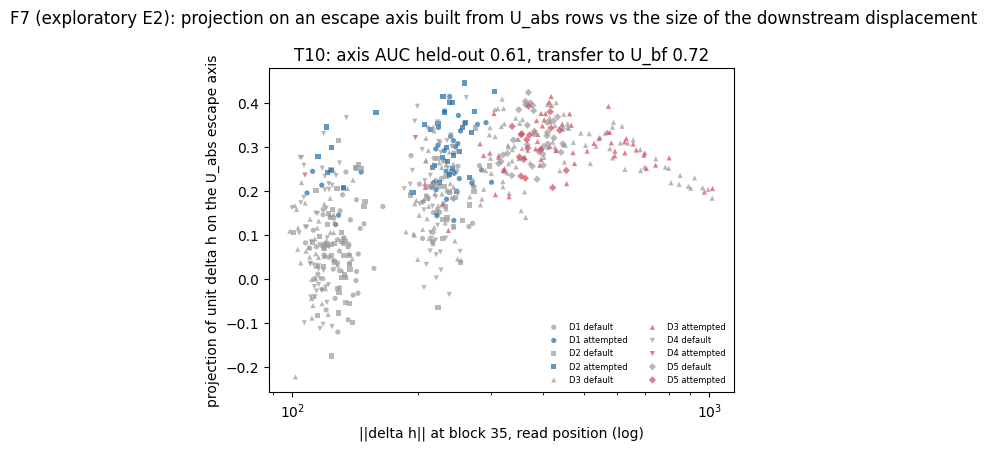

10:17:54|INFO   |{'T10': {'n': 600, 'n_attempted': 142, 'cv_auc_log_norms': 0.7456639399717079, 'cv_auc_R35_direction': 0.7156805461590504, 'fixed_dose_strata': {'U_abs_alpha2 (D1+D2)': {'n': 100, 'n_attempted': 52, 'cv_auc_log_norms': 0.5232371794871795, 'cv_auc_R35_direction': 0.4014423076923077}, 'U_bf_family_alpha2 (D3+D4+D5)': {'n': 150, 'n_attempted': 23, 'cv_auc_log_norms': 0.6881205066757959, 'cv_auc_R35_direction': 0.7254364943512496}}}, 'slot_concordance': {'T10|Y|alpha2': {'n_slots': 50, 'phi_D1_D2_same_stream_diff_u': 0.16012815380508702, 'joint_D1_D2': 15, 'joint_expected_if_independent': 13.0, 'phi_D1_D3_same_u_diff_unit': 0.20000000000000015, 'phi_D2_D4_same_u_diff_unit': 0.1372527032615032}, 'T10|A|alpha2': {'n_slots': 50, 'phi_D1_D2_same_stream_diff_u': 0.19871794871794848, 'joint_D1_D2': 16, 'joint_expected_if_independent': 13.520000000000001, 'phi_D1_D3_same_u_diff_unit': 0.1868161794392684, 'phi_D2_D4_same_u_diff_unit': 0.1372527032615032}, 'T10|A|D1_alpha1_to_alpha

10:17:54|INFO   |{'T10': {'built_on': 'U_abs designs D1, D2 at alpha 1-2 (attempted vs default)', 'auc_heldout_templates_U_abs': 0.607977207977208, 'auc_transfer_to_U_bf_family': 0.7230911503357323, 'mean_projection_attempted_vs_default_U_bf': [0.29509463906288147, 0.20105552673339844]}}


E2 in 2.2s


In [20]:
@logger.catch(reraise=True)
def geometry_main() -> None:   # src/geometry_k.py main()
    rows = {r["key"]: r for r in load_joined() if r.get("labelled")}
    vecs = load_vectors()
    out: dict = {}
    # original: plt.subplots(1, 2, figsize=(12, 4.2)) over ("T10", "T2"); the mini data ships T10's vectors only
    fig, axes = plt.subplots(1, len(GEOMETRY_TASKS), figsize=(6 * len(GEOMETRY_TASKS), 4.2), squeeze=False)
    for ax, task in zip(axes[0], GEOMETRY_TASKS):
        sel = [k for k in vecs if k in rows and rows[k]["task"] == task and rows[k]["design"] in
               ("D1", "D2", "D3", "D4", "D5") and all(f in vecs[k] for f in ("R35",))   # original: R35, smean35, gen1_35
               and rows[k]["k"] in COMMITTED_KS.get((task, rows[k]["alpha"]), list(range(10)))]
        if len(sel) < 40:
            continue
        y = np.array([rows[k]["A"] for k in sel])
        R = np.stack([vecs[k]["R35"] for k in sel])
        # G = np.stack([vecs[k]["gen1_35"] for k in sel])   # notebook: not shipped in the mini data
        # S = np.stack([vecs[k]["smean35"] for k in sel])   # notebook: not shipped; its norm is the logged S_b35
        S_norm = np.array([rows[k]["realised_disp"]["S_b35"] for k in sel])
        norms = np.column_stack([np.log(S_norm), np.log(np.linalg.norm(R, axis=1))])
        res = {"n": len(sel), "n_attempted": int(y.sum()),
               "cv_auc_log_norms": cv_auc(norms, y, pca=None),
               "cv_auc_R35_direction": cv_auc(unit_rows(R), y)}
        #      "cv_auc_gen1_direction": cv_auc(unit_rows(G), y),          (needs gen1_35)
        #      "cv_auc_specmean35_direction": cv_auc(unit_rows(S), y)}    (needs smean35)
        # (b) escape axis built on U_abs rows only (alpha 1-2), 2-fold by template for its own AUC
        des = np.array([rows[k]["design"] for k in sel])
        alp = np.array([rows[k]["alpha"] for k in sel])
        # (a') the same comparison at a FIXED unit family and dose (alpha 2), so dose cannot drive the norm AUC
        strata = {}
        for name, m in (("U_abs_alpha2 (D1+D2)", np.isin(des, ("D1", "D2")) & (alp == 2.0)),
                        ("U_bf_family_alpha2 (D3+D4+D5)", np.isin(des, ("D3", "D4", "D5")) & (alp == 2.0))):
            if m.sum() >= 40:
                strata[name] = {"n": int(m.sum()), "n_attempted": int(y[m].sum()),
                                "cv_auc_log_norms": cv_auc(norms[m], y[m], pca=None),
                                "cv_auc_R35_direction": cv_auc(unit_rows(R[m]), y[m], pca=16)}
                #               "cv_auc_gen1_direction": cv_auc(unit_rows(G[m]), y[m], pca=16)}   (needs gen1_35)
        res["fixed_dose_strata"] = strata
        tmpl = np.array([rows[k]["template"] for k in sel])
        Ru = unit_rows(R)
        absm = np.isin(des, ("D1", "D2")) & np.isin(alp, (1.0, 2.0))
        own = np.zeros(len(sel))
        for fold in (("W1", "W2"), ("W3", "W4", "W5")):
            tr = absm & ~np.isin(tmpl, fold)
            te = absm & np.isin(tmpl, fold)
            ax_ = Ru[tr & (y == 1)].mean(0) - Ru[tr & (y == 0)].mean(0)
            own[te] = Ru[te] @ (ax_ / np.linalg.norm(ax_))
        axis = Ru[absm & (y == 1)].mean(0) - Ru[absm & (y == 0)].mean(0)
        axis /= np.linalg.norm(axis)
        proj = Ru @ axis
        bfm = np.isin(des, ("D3", "D4", "D5"))
        res["escape_axis"] = {"built_on": "U_abs designs D1, D2 at alpha 1-2 (attempted vs default)",
                              "auc_heldout_templates_U_abs": auc(own[absm], y[absm]),
                              "auc_transfer_to_U_bf_family": auc(proj[bfm], y[bfm]),
                              "mean_projection_by_design_alpha": {
                                  f"{d}_a{a:g}": float(proj[(des == d) & (alp == a)].mean())
                                  for d in ("D1", "D2", "D3", "D4", "D5") for a in sorted(set(alp))
                                  if ((des == d) & (alp == a)).any()},
                              "mean_projection_attempted_vs_default_U_bf": [
                                  float(proj[bfm & (y == 1)].mean()) if (bfm & (y == 1)).any() else None,
                                  float(proj[bfm & (y == 0)].mean()) if (bfm & (y == 0)).any() else None]}
        out[task] = res
        rn = np.linalg.norm(R, axis=1)
        for d, mk in (("D1", "o"), ("D2", "s"), ("D3", "^"), ("D4", "v"), ("D5", "D")):
            for yy, c in ((0, "#9a9a9a"), (1, "#1b6ca8" if d in ("D1", "D2") else "#d1495b")):
                m = (des == d) & (y == yy)
                if m.any():
                    ax.scatter(rn[m], proj[m], marker=mk, s=14, color=c, alpha=0.7, edgecolor="none",
                               label=f"{d} {'attempted' if yy else 'default'}")
        ax.set_xscale("log")
        ax.set_xlabel("||delta h|| at block 35, read position (log)")
        ax.set_ylabel("projection of unit delta h on the U_abs escape axis")
        ax.set_title(f"{task}: axis AUC held-out {res['escape_axis']['auc_heldout_templates_U_abs']:.2f}, "
                     f"transfer to U_bf {res['escape_axis']['auc_transfer_to_U_bf_family'] or float('nan'):.2f}")
        ax.legend(frameon=False, fontsize=6, ncol=2, loc="lower right")
    fig.suptitle("F7 (exploratory E2): projection on an escape axis built from U_abs rows vs the size of the downstream displacement",
                 y=1.02)
    plt.show()   # original: fig.savefig(FIGS / "F7_escape_axis.pdf" | ".png")
    out["slot_concordance"] = slot_concordance()
    write_json(RESULTS / "e2_geometry.json", out)
    logger.info({t: {k: v for k, v in r.items() if k not in ("escape_axis",)} for t, r in out.items()})
    # notebook fix: `if "escape_axis" in r` added; without it this line raises KeyError on the slot_concordance entry
    # (as it did in the original run, after e2_geometry.json and F7 had been written)
    logger.info({t: {k: v for k, v in r["escape_axis"].items() if k != "mean_projection_by_design_alpha"}
                 for t, r in out.items() if "escape_axis" in r})


t0 = time.time()
geometry_main()
print(f"E2 in {time.time() - t0:.1f}s")

## 6. Figures (`src/figures_k.py`)

The figure functions are verbatim. The notebook changes are:

- `save()` shows each figure inline instead of writing `figures/<name>.pdf|png`;
- F2 reads `cache/units/T10.npz` from the mini data;
- F5 takes its vectors from `load_vectors()` and draws T10 only;
- E1 reads the in-memory `e1_sweep` result.

F6 (S3 prices) and E3 (fresh-slot replication) are not drawn: their inputs (iteration 5's knob rows, T10 slots k 10–19, T03) are outside the mini data.

**F1: the S1 interaction.** Shares of correct, named off-default programs (Y, Wilson 95%) per task and α. The dose unit is on the x-axis; the two seed schemes are the two lines, and U_bf* stands beside them. If the seeds mattered, the lines would separate. If the unit matters, both lines fall from U_abs to U_bf.

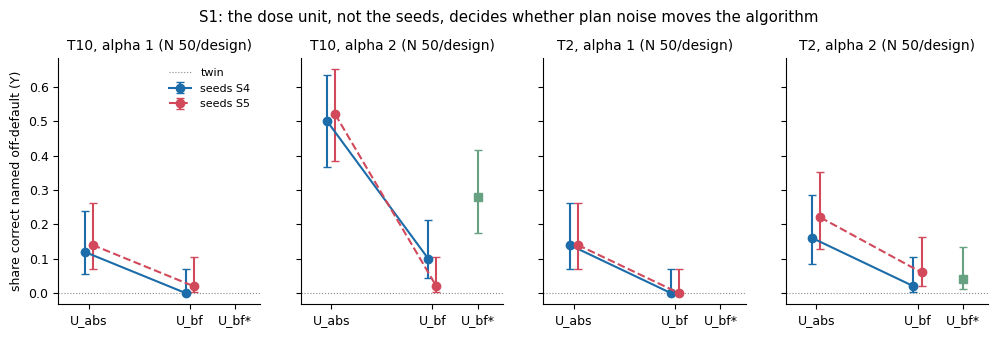

10:17:54|INFO   |figure F1_s1_interaction


In [21]:
# ---- src/figures_k.py ----
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
COL = {"D1": "#1b6ca8", "D2": "#5fa8d3", "D3": "#d1495b", "D4": "#edae49", "D5": "#66a182", "PTOP": "#2e294e",
       "PREST": "#8d6a9f", "PSHUF": "#999999", "TWIN": "#444444"}
NAME = {"D1": "D1 U_abs x S4", "D2": "D2 U_abs x S5", "D3": "D3 U_bf x S4", "D4": "D4 U_bf x S5",
        "D5": "D5 U_bf* x S4", "PTOP": "P_top", "PREST": "P_rest", "PSHUF": "P_shuf"}


def save(fig, name: str) -> None:
    plt.show()   # notebook: inline instead of fig.savefig(FIGS / f"{name}.pdf"), (FIGS / f"{name}.png", dpi=170)
    logger.info(f"figure {name}")


def f1(rows) -> None:
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
    for ax, (task, alpha) in zip(axes, [("T10", 1.0), ("T10", 2.0), ("T2", 1.0), ("T2", 2.0)]):
        a = "a1" if alpha == 1 else "a2"
        for seeds, (du, db), ls in (("S4", ("D1", "D3"), "-"), ("S5", ("D2", "D4"), "--")):
            ys, lo, hi = [], [], []
            for d in (du, db):
                c = cell(rows, task, f"{d}_{a}", COMMITTED_KS[(task, alpha)])
                k = sum(r["Y"] for r in c.values())
                n = len(c)
                ys.append(k / n if n else np.nan)
                l, h = wilson(k, n)
                lo.append(max(0.0, ys[-1] - l))
                hi.append(max(0.0, h - ys[-1]))
            x = np.array([0, 1]) + (-0.04 if seeds == "S4" else 0.04)
            ax.errorbar(x, ys, yerr=[lo, hi], fmt="o", ls=ls, color="#1b6ca8" if seeds == "S4" else "#d1495b",
                        capsize=3, label=f"seeds {seeds}")
        c5 = cell(rows, task, f"D5_{a}", COMMITTED_KS[(task, alpha)])
        if c5:
            k = sum(r["Y"] for r in c5.values())
            n = len(c5)
            l, h = wilson(k, n)
            ax.errorbar([1.45], [k / n], yerr=[[max(0.0, k / n - l)], [max(0.0, h - k / n)]], fmt="s", color=COL["D5"], capsize=3,
                        label="U_bf* x S4 (D5)")
        tw = cell(rows, task, "TWIN", K20 if task == "T2" else K10)
        ax.axhline(sum(r["Y"] for r in tw.values()) / max(len(tw), 1), color="#888", lw=0.8, ls=":", label="twin")
        ax.set_xticks([0, 1, 1.45])
        ax.set_xticklabels(["U_abs", "U_bf", "U_bf*"])
        ax.set_title(f"{task}, alpha {int(alpha)} (N {len(cell(rows, task, f'D1_{a}', COMMITTED_KS[(task, alpha)]))}/design)")
        ax.set_xlim(-0.3, 1.7)
    axes[0].set_ylabel("share correct named off-default (Y)")
    axes[0].legend(loc="upper right", frameon=False)
    fig.suptitle("S1: the dose unit, not the seeds, decides whether plan noise moves the algorithm", y=1.03)
    save(fig, "F1_s1_interaction")


f1(rows)

**F2: the dose units in activation coordinates.** Each panel is a [block 12–23 × T10 task-spec token] map of how far the edit pushes each cell at α = 1, in the same units as the residual-stream norm ‖h_twin‖ shown in the top panel.

- **U_abs** is peaky: its top quartile of cells holds 81% of its energy, in bands on a few task tokens. Its peak dose at α 2 is about 2× the cell's own residual norm.
- **U_bf** is flat by construction: 42% of its energy in the top quartile, peak dose 0.25× the residual norm.
- **U_bf\*** keeps U_bf's flat shape at U_abs's per-block energy. **P_top**, **P_rest** and **P_shuf** split U_abs's energy by *where* it lands.

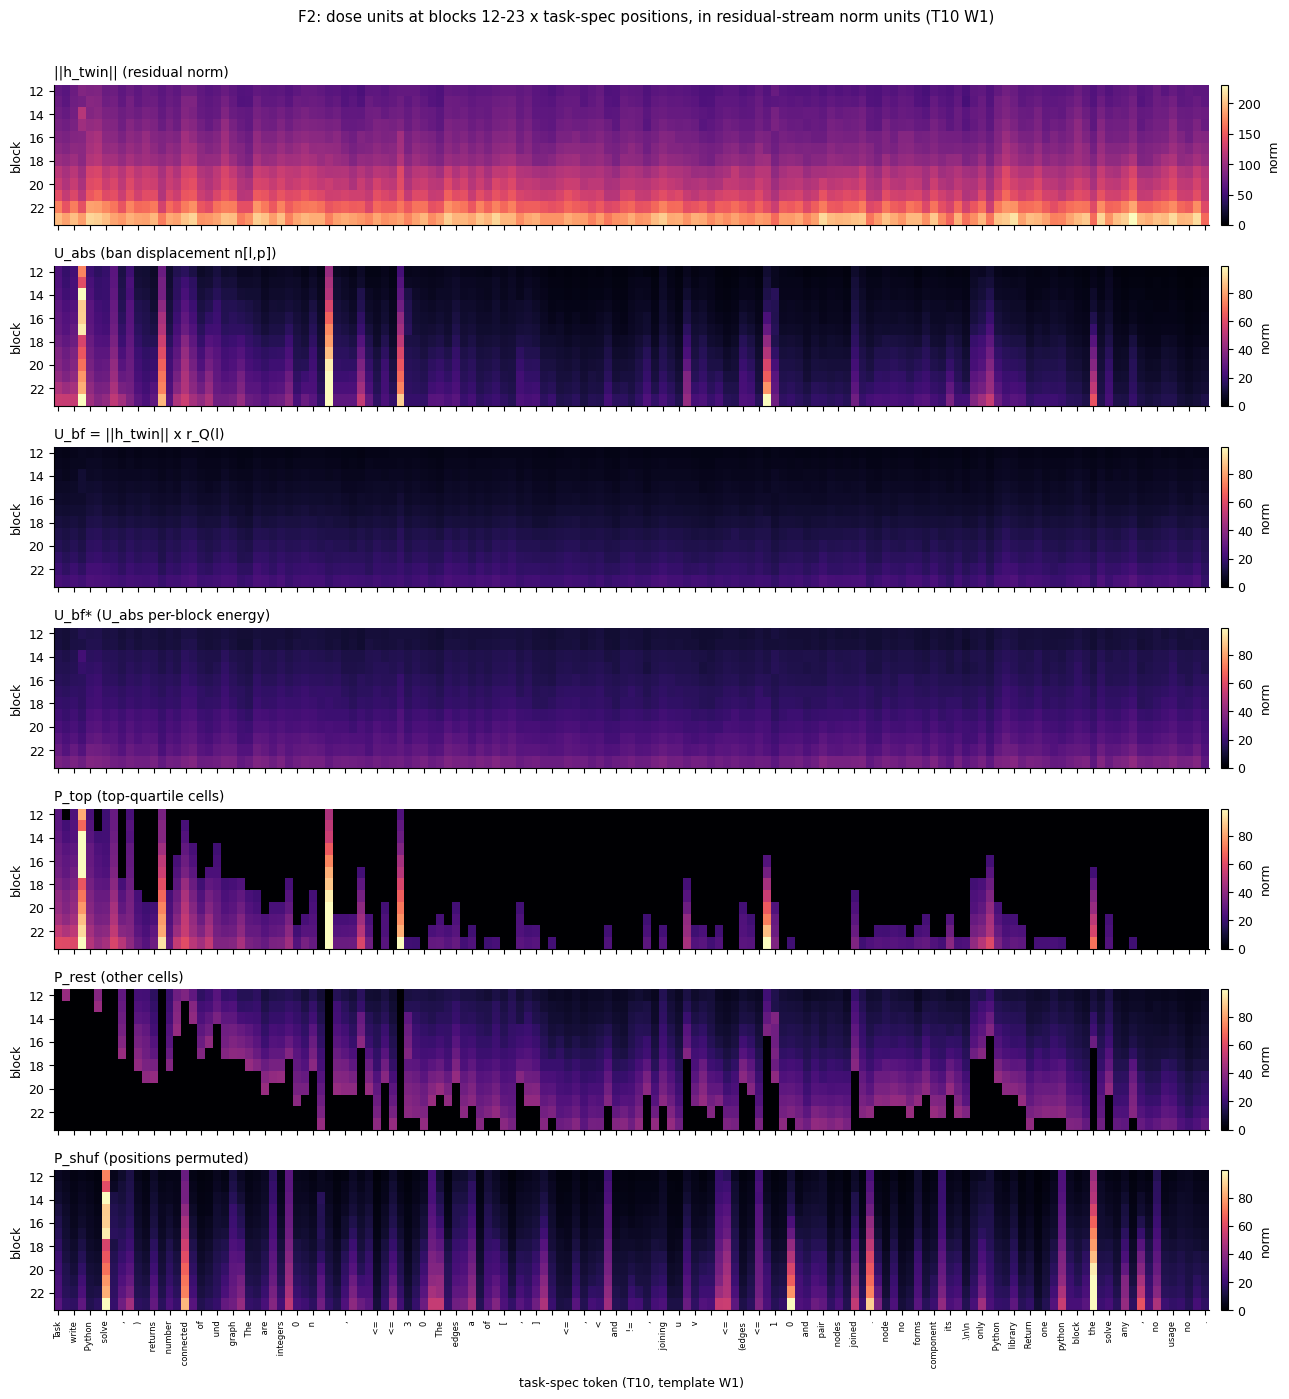

10:17:55|INFO   |figure F2_unit_heatmaps


In [22]:
def f2() -> None:
    z = UNITS["T10"]   # notebook: cache/units/T10.npz (src/dump_units.py) from the mini data
    toks = [t.replace("\n", "\\n") for t in z["tokens_W1"]]
    mats = [("||h_twin|| (residual norm)", z["h_norm_W1"]), ("U_abs (ban displacement n[l,p])", z["U_abs"]),
            ("U_bf = ||h_twin|| x r_Q(l)", z["U_bf_W1"]), ("U_bf* (U_abs per-block energy)", z["U_bf_star_W1"]),
            ("P_top (top-quartile cells)", z["P_top"]), ("P_rest (other cells)", z["P_rest"]),
            ("P_shuf (positions permuted)", z["P_shuf"])]
    fig, axes = plt.subplots(len(mats), 1, figsize=(13, 2.0 * len(mats)), sharex=True)
    vmax = max(float(np.percentile(m, 99.5)) for _, m in mats[1:])
    for ax, (title, m) in zip(axes, mats):
        im = ax.imshow(m, aspect="auto", cmap="magma", vmin=0, vmax=(None if title.startswith("||h") else vmax),
                       interpolation="nearest")
        ax.set_yticks(range(0, 12, 2))
        ax.set_yticklabels([str(12 + i) for i in range(0, 12, 2)])
        ax.set_ylabel("block")
        ax.set_title(title, loc="left")
        plt.colorbar(im, ax=ax, pad=0.01, fraction=0.02, label="norm")
    step = max(1, len(toks) // 60)
    axes[-1].set_xticks(range(0, len(toks), step))
    axes[-1].set_xticklabels([toks[i][:10] for i in range(0, len(toks), step)], rotation=90, fontsize=6)
    axes[-1].set_xlabel("task-spec token (T10, template W1)")
    fig.suptitle("F2: dose units at blocks 12-23 x task-spec positions, in residual-stream norm units (T10 W1)", y=0.995)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save(fig, "F2_unit_heatmaps")


f2()

**F3: what the edit does downstream, block by block.** The realised displacement ‖Δh‖ against the clean twin, logged by the real model, at blocks 12–35 for every design at α 2 (mean over rows). It is taken at three places: the spec-mean, the read position R, and generated position 1. The grey band marks the edited blocks; blocks 0–11 are exactly 0.

By block 35 U_abs and U_bf leave displacements of about the same size, yet U_abs escapes 5–25× more often.

**F4: outcome against downstream displacement size.** One point per program (α 1 and 2). The outcome is plotted against its block-35 read-position displacement, jittered vertically. Escapes are not explained by a larger downstream push.

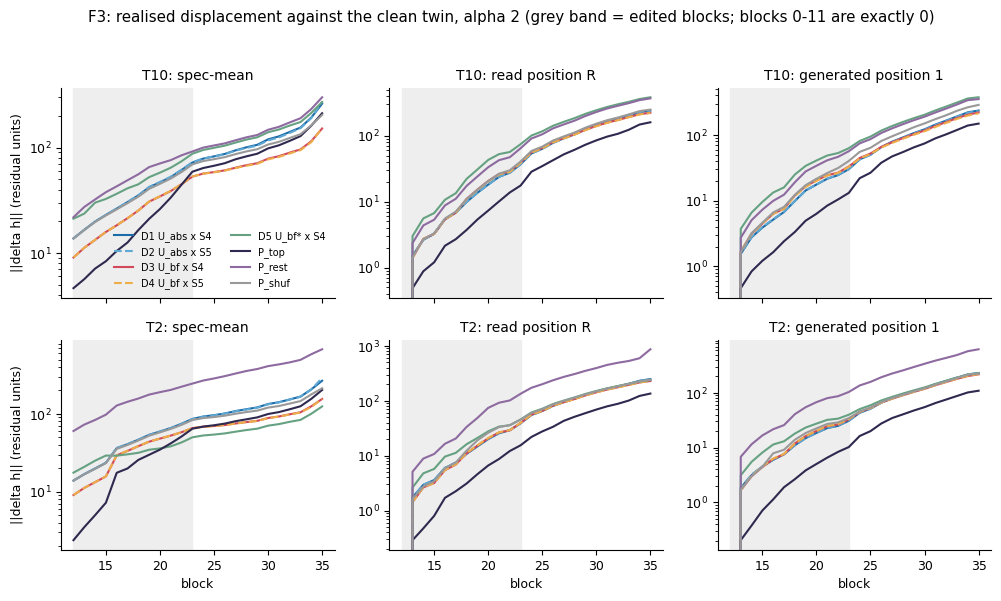

10:17:56|INFO   |figure F3_displacement_blocks


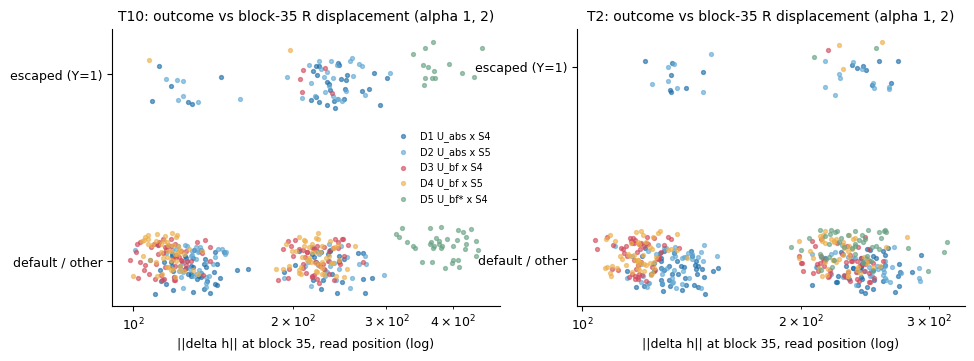

10:17:56|INFO   |figure F4_escape_vs_disp


In [23]:
def f3() -> None:
    rec = read_jsonl(REALISED)
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
    for i, task in enumerate(("T10", "T2")):
        for j, (fld, lab) in enumerate((("spec_mean", "spec-mean"), ("R", "read position R"),
                                        ("gen1", "generated position 1"))):
            ax = axes[i, j]
            by = defaultdict(list)
            for r in rec:
                if r["task"] == task and r.get("alpha") == 2.0 and r.get(fld):
                    by[r["design"]].append(r[fld])
            for d in ("D1", "D2", "D3", "D4", "D5", "PTOP", "PREST", "PSHUF"):
                if by.get(d):
                    m = np.mean(np.array(by[d]), axis=0)
                    ax.plot(range(12, 36), m[12:], color=COL[d], label=NAME[d],
                            ls="--" if d in ("D2", "D4") else "-")
            ax.set_yscale("log")
            ax.axvspan(12, 23, color="#eee", zorder=0)
            ax.set_title(f"{task}: {lab}")
            if j == 0:
                ax.set_ylabel("||delta h|| (residual units)")
            if i == 1:
                ax.set_xlabel("block")
    axes[0, 0].legend(frameon=False, ncol=2, fontsize=7)
    fig.suptitle("F3: realised displacement against the clean twin, alpha 2 (grey band = edited blocks; blocks 0-11 are exactly 0)", y=1.01)
    save(fig, "F3_displacement_blocks")


def f4(rows) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    rng = np.random.default_rng(0)
    for ax, task in zip(axes, ("T10", "T2")):
        for i, d in enumerate(("D1", "D2", "D3", "D4", "D5")):
            sel = [r for r in rows if r["task"] == task and r["design"] == d and r.get("labelled")
                   and r.get("realised_disp") and r["alpha"] in (1.0, 2.0)]
            if not sel:
                continue
            x = np.array([r["realised_disp"]["R_b35"] for r in sel])
            y = np.array([r["Y"] for r in sel]) + rng.uniform(-0.12, 0.12, len(sel)) + (i - 2) * 0.03
            ax.scatter(x, y, s=8, alpha=0.6, color=COL[d], label=NAME[d])
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["default / other", "escaped (Y=1)"])
        ax.set_xscale("log")
        ax.set_xlabel("||delta h|| at block 35, read position (log)")
        ax.set_title(f"{task}: outcome vs block-35 R displacement (alpha 1, 2)")
    axes[0].legend(frameon=False, fontsize=7, loc="center right")
    save(fig, "F4_escape_vs_disp")


f3()
f4(rows)

**F5: the downstream displacements in residual-stream coordinates.** The block-35 read-position displacement vectors (4096-d, as logged by the real model) of every α-2 program, projected on their first two principal components. Colour is the algorithm the program implemented; marker is the design. P_rest is excluded because it breaks T2 and would own PC1 there.

The published figure used n 700 on T10, because `f5` also picks up the exploratory fresh slots k 10–19. Here only k 0–9 are used, n 350.

What to look for:

- The first two components carry only about a tenth and a twentieth of the variance, so the displacement cloud is high-dimensional.
- The visible structure is by design: the U_bf* (D5) rows spread out along PC1.
- DFS and BFS escapes interleave with union-find programs inside the shared cloud instead of forming a cluster of their own. This agrees with E2: at a fixed dose, the direction of the downstream displacement does not predict which sample escapes.

**E1: dose response of the ban-free unit.** The share Y and pass rate are plotted against α, and against the realised block-35 displacement, for U_bf (D3, α 1–6) next to U_abs (D1, α 1–2). U_bf needs about α 4 to approach what U_abs does at α 2. By then it pays a larger downstream displacement, and at α 6 it breaks the programs.

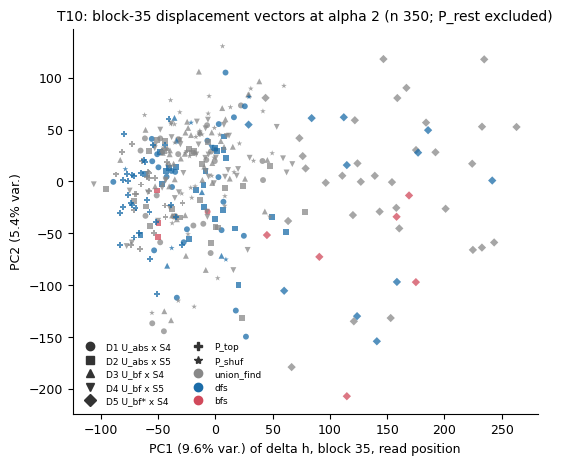

10:17:56|INFO   |figure F5_pca_disp35


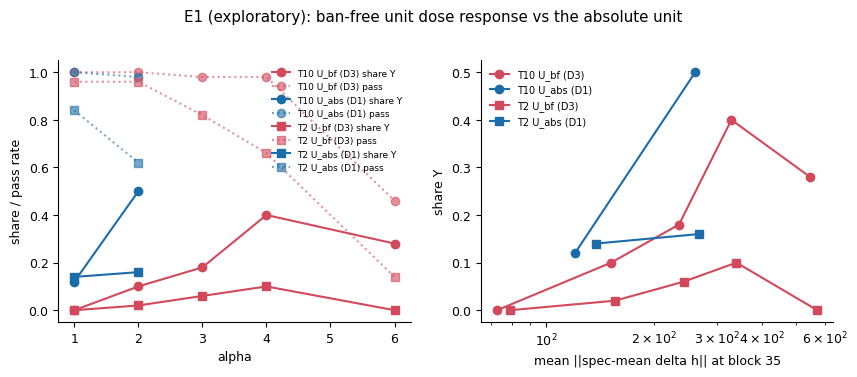

10:17:56|INFO   |figure E1_dose_response


In [24]:
def f5(rows) -> None:
    lab = {r["key"]: r for r in rows}
    vecs = defaultdict(dict)
    for key, kinds in load_vectors().items():   # notebook: the R35 vectors of cache/disp/*.npz shipped in the mini data
        if "R35" in kinds:
            vecs[key.split("|")[0]][key] = kinds["R35"]
    # original: plt.subplots(1, 2, figsize=(12, 5)) over ("T10", "T2"); the mini data ships T10's vectors only
    fig, axes = plt.subplots(1, len(GEOMETRY_TASKS), figsize=(6 * len(GEOMETRY_TASKS), 5), squeeze=False)
    marks = {"D1": "o", "D2": "s", "D3": "^", "D4": "v", "D5": "D", "PTOP": "P", "PREST": "X", "PSHUF": "*"}
    cmap = {"union_find": "#888888", "dfs": "#1b6ca8", "bfs": "#d1495b", "dijkstra": "#888888", "bf_spfa": "#1b6ca8",
            "other": "#66a182", "invalid": "#edae49", "floyd": "#8d6a9f", "disputed": "#000000"}
    for ax, task in zip(axes[0], GEOMETRY_TASKS):
        keys = [k for k in vecs.get(task, {}) if k in lab and lab[k].get("labelled") and lab[k]["alpha"] == 2.0
                and lab[k]["design"] != "PREST"]     # P_rest breaks T2 (pass 0) and would own PC1
        if len(keys) < 10:
            continue
        X = np.stack([vecs[task][k] for k in keys])
        Xc = X - X.mean(0)
        U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
        pcs = Xc @ Vt[:2].T
        ev = (S ** 2) / (S ** 2).sum()
        for d, mk in marks.items():
            for lb, c in cmap.items():
                idx = [i for i, k in enumerate(keys) if lab[k]["design"] == d and lab[k]["label"] == lb]
                if idx:
                    ax.scatter(pcs[idx, 0], pcs[idx, 1], marker=mk, s=18, color=c, alpha=0.75, edgecolor="none")
        from matplotlib.lines import Line2D
        h1 = [Line2D([], [], marker=mk, ls="", color="#333", label=NAME[d]) for d, mk in marks.items()
              if any(lab[k]["design"] == d for k in keys)]
        h2 = [Line2D([], [], marker="o", ls="", color=c, label=lb) for lb, c in cmap.items()
              if any(lab[k]["label"] == lb for k in keys)]
        ax.legend(handles=h1 + h2, frameon=False, fontsize=6.5, ncol=2, loc="best")
        ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% var.) of delta h, block 35, read position")
        ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}% var.)")
        ax.set_title(f"{task}: block-35 displacement vectors at alpha 2 (n {len(keys)}; P_rest excluded)")
    save(fig, "F5_pca_disp35")


def e1() -> None:
    r = RESULTS_MEM.get("e1_sweep")   # notebook: the in-memory result of e1_sweep() (results/e1_sweep.json)
    if not r:
        return
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for task, mk in (("T10", "o"), ("T2", "s")):
        d = r.get(task, {})
        for unit, arms, c in (("U_bf (D3)", ["D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6"], "#d1495b"),
                              ("U_abs (D1)", ["D1_a1", "D1_a2"], "#1b6ca8")):
            xs = [float(a.split("_a")[1]) for a in arms if a in d]
            ys = [d[a]["Y"]["share"] for a in arms if a in d]
            ps = [d[a]["pass_rate"] for a in arms if a in d]
            dx = [d[a]["realised_mean"]["S_b35"] for a in arms if a in d and d[a].get("realised_mean")]
            axes[0].plot(xs, ys, marker=mk, color=c, label=f"{task} {unit} share Y")
            axes[0].plot(xs, ps, marker=mk, color=c, ls=":", alpha=0.6, label=f"{task} {unit} pass")
            if len(dx) == len(ys):
                axes[1].plot(dx, ys, marker=mk, color=c, label=f"{task} {unit}")
    axes[0].set_xlabel("alpha")
    axes[0].set_ylabel("share / pass rate")
    axes[0].legend(frameon=False, fontsize=6.5)
    axes[1].set_xlabel("mean ||spec-mean delta h|| at block 35")
    axes[1].set_ylabel("share Y")
    axes[1].set_xscale("log")
    axes[1].legend(frameon=False, fontsize=7)
    fig.suptitle("E1 (exploratory): ban-free unit dose response vs the absolute unit", y=1.03)
    save(fig, "E1_dose_response")


f5(rows)
e1()

## 7. Results: re-derived numbers against the published ones

The table puts every headline number this notebook re-derived next to the value in the artifact's `results/*.json`.

**When to expect an exact match.** At the original values (`K_USE` = k 0–9, `N_BOOT` = 2000, `N_FLIP` = 100,000), 32 of the 33 compared quantities come out identical to the published ones. Identical means the same anchors, shares, contrasts, bootstrap CIs, sign-flip and Holm p, conditional-logit β, D5 split, McNemar counts, decision, D*, E1 share and E2 escape-axis AUCs.

The one exception is E2's cross-validated AUC from the R35 direction (0.721 vs 0.727). Its PCA step uses scikit-learn's randomized solver without a fixed seed, so it moves in the third decimal across runs and library versions; the table marks it "close" (within 1%). With smaller demo values, the counts and shares cover fewer slots, and the CIs and Monte-Carlo p's are coarser.

**Committed predictions.** The second table checks the predictions of COMMIT #1 against this run's numbers, using each prediction's own stated criterion.

**Figure.** The plot shows the experiment's central contrast in activation units. For every arm it puts the escape share (Y, Wilson 95%) against the mean size of the realised displacement at block 35. If the downstream displacement *size* decided escapes, the U_abs and U_bf points would fall on one curve. They do not: at matched downstream size, U_abs escapes far more often.

K_USE = k 0-9 (100 slots), N_BOOT = 2000, N_FLIP = 100000: 32 of 33 comparable quantities identical, 1 within 1%

                                         quantity                    notebook                   published  same
A1: D1 T10 a2 attempted off-default (exp29 25/50)                          26                          26   yes
   A2: D4 T10 a2 correct off-default (exp27 1/50)                           1                           1   yes
    D1 T10 a2 per-slot label agreement with exp29                       0.980                       0.980   yes
                               T10 a2 share Y, D1                       0.500                       0.500   yes
                               T10 a2 share Y, D2                       0.520                       0.520   yes
                               T10 a2 share Y, D3                       0.100                       0.100   yes
                               T10 a2 share Y, D4                       0.020                       0.

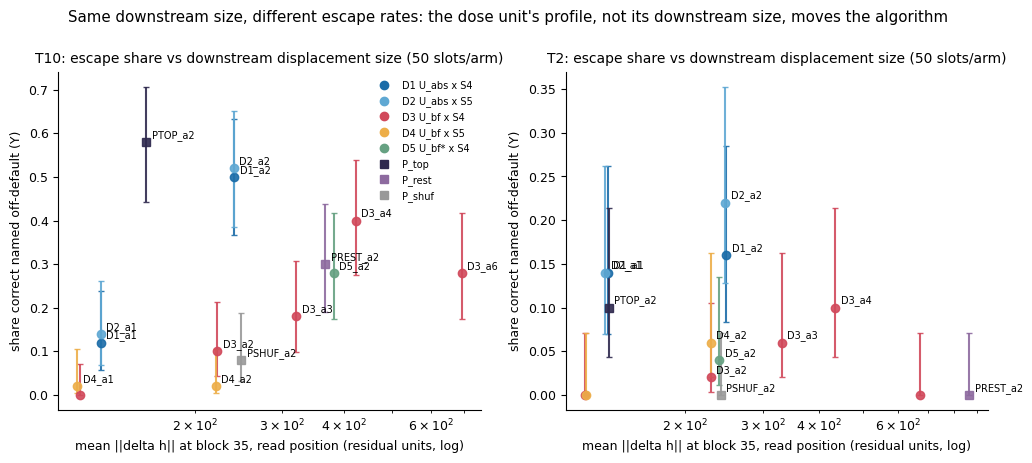

In [25]:
pub = data["published"]
S1, S2, E2 = RESULTS_MEM["s1_2x2"], RESULTS_MEM["s2_profile"], RESULTS_MEM["e2_geometry"]
ANC, E1 = RESULTS_MEM["anchors"], RESULTS_MEM["e1_sweep"]


def g(d: Any, *path: str) -> Any:
    for p in path:
        if not isinstance(d, dict) or p not in d:
            return None
        d = d[p]
    return d


def ci(c: list | tuple | None) -> str | None:
    return None if c is None else f"[{c[0]:+.2f}, {c[1]:+.2f}]"


def mc(t: dict | None) -> str | None:
    return None if t is None else f"{t['share_x']:.2f} vs {t['share_y']:.2f}, McNemar {t['n10']}:{t['n01']}"


T, PT, D5p = "T10|a2|Y", ("s1_tables", "T10|a2|Y"), "profile_at_matched_energy (D1 - D5)"
lines = [
    ("A1: D1 T10 a2 attempted off-default (exp29 25/50)", g(ANC, "A1", "attempted_off_default"),
     g(pub, "anchors", "A1", "attempted_off_default")),
    ("A2: D4 T10 a2 correct off-default (exp27 1/50)", g(ANC, "A2", "correct_off_default"),
     g(pub, "anchors", "A2", "correct_off_default")),
    ("D1 T10 a2 per-slot label agreement with exp29", g(ANC, "D1_T10_per_slot_agreement_vs_exp29", "agreement"),
     g(pub, "anchors", "D1_T10_per_slot_agreement_vs_exp29", "agreement")),
    *[(f"T10 a2 share Y, {d}", g(S1, "tables", T, "shares", d), g(pub, *PT, "shares", d)) for d in ("D1", "D2", "D3", "D4")],
    *[(f"T10 a2 {lab} RD", g(S1, "tables", T, f"RD_{c}"), g(pub, *PT, f"RD_{c}"))
      for c, lab in (("unit", "unit"), ("seed", "seed"), ("int", "interaction"))],
    *[(f"T10 a2 {lab} RD 95% CI", ci(g(S1, "tables", T, f"RD_{c}_ci95")), ci(g(pub, *PT, f"RD_{c}_ci95")))
      for c, lab in (("unit", "unit"), ("seed", "seed"), ("int", "interaction"))],
    ("T10 a2 Holm p, unit", g(S1, "tables", T, "holm", "unit"), g(pub, *PT, "holm", "unit")),
    ("T10 a2 conditional-logit beta_unit", g(S1, "tables", T, "clogit", "coef", "unit"), g(pub, *PT, "clogit_coef", "unit")),
    ("decision T10 a2 (committed rule)", S1.get("decision_T10_a2"), pub["decision_T10_a2"]),
    ("T10 a1 unit RD", g(S1, "tables", "T10|a1|Y", "RD_unit"), g(pub, "s1_tables", "T10|a1|Y", "RD_unit")),
    ("T10 a2 unit RD on attempts A", g(S1, "tables", "T10|a2|A", "RD_unit"), g(pub, "s1_tables", "T10|a2|A", "RD_unit")),
    ("T2 a2 unit RD (k 0-9)", g(S1, "tables", "T2|a2|Y", "RD_unit"), g(pub, "s1_tables", "T2|a2|Y|k0-9", "RD_unit")),
    ("T2 a2 unit RD 95% CI (k 0-9)", ci(g(S1, "tables", "T2|a2|Y", "RD_unit_ci95")),
     ci(g(pub, "s1_tables", "T2|a2|Y|k0-9", "RD_unit_ci95"))),
    ("D5 = U_bf* T10 a2 share Y", g(S1, "D5_split", "T10|Y", "shares", "D5"), g(pub, "D5_split_T10_Y", "shares", "D5")),
    ("D5 split: profile at matched energy (D1 - D5)", g(S1, "D5_split", "T10|Y", D5p, "RD"),
     g(pub, "D5_split_T10_Y", D5p, "RD")),
    ("D5 split: energy at ban-free shape (D5 - D3)", g(S1, "D5_split", "T10|Y", "energy_at_banfree_shape (D5 - D3)", "RD"),
     g(pub, "D5_split_T10_Y", "energy_at_banfree_shape (D5 - D3)", "RD")),
    ("S2 T10: P_top vs P_rest (share Y)", mc(g(S2, "T10", "tests", "PTOP_vs_PREST|Y")),
     mc(g(pub, "s2_T10", "tests", "PTOP_vs_PREST|Y"))),
    ("S2 T10: D1 vs P_shuf (share Y)", mc(g(S2, "T10", "tests", "D1_vs_PSHUF|Y")),
     mc(g(pub, "s2_T10", "tests", "D1_vs_PSHUF|Y"))),
    ("S2 reading (committed)", S2.get("reading_T10"), g(pub, "s2_T10", "reading_T10")),
    ("D* (COMMIT #2 rule)", dstar_res["D_star"], pub["D_star"]),
    ("E1 T10: U_bf (D3) at alpha 4, share Y", g(E1, "T10", "D3_a4", "Y", "share"), g(pub, "e1_T10_share_Y", "D3_a4")),
    ("E2 T10: rows with block-35 vectors", g(E2, "T10", "n"), g(pub, "e2_T10", "n")),
    ("E2 T10: CV AUC of A from the R35 direction", g(E2, "T10", "cv_auc_R35_direction"),
     g(pub, "e2_T10", "cv_auc_R35_direction")),
    ("E2 T10: escape-axis AUC, held-out templates", g(E2, "T10", "escape_axis", "auc_heldout_templates_U_abs"),
     g(pub, "e2_T10", "escape_axis", "auc_heldout_templates_U_abs")),
    ("E2 T10: escape-axis AUC, transfer to U_bf rows", g(E2, "T10", "escape_axis", "auc_transfer_to_U_bf_family"),
     g(pub, "e2_T10", "escape_axis", "auc_transfer_to_U_bf_family")),
    ("E2 T10: phi(D1, D2), same stream, different u", g(E2, "slot_concordance", "T10|Y|alpha2", "phi_D1_D2_same_stream_diff_u"),
     g(pub, "e2_slot_concordance_T10", "T10|Y|alpha2", "phi_D1_D2_same_stream_diff_u")),
]


def show(v: Any) -> str:
    if v is None:
        return "n/a"
    if isinstance(v, float):
        return f"{v:.2e}" if 0 < abs(v) < 1e-2 else f"{v:.3f}"
    return str(v)


def same(a: Any, b: Any) -> str:
    if a is None or b is None:
        return ""
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        if abs(a - b) <= 1e-9 + 1e-9 * abs(b):
            return "yes"
        return "close" if abs(a - b) <= 0.01 + 0.01 * abs(b) else "no"   # within 1% (solver / library tolerance)
    return "yes" if a == b else "no"


summary = pd.DataFrame([{"quantity": q, "notebook": show(a), "published": show(b), "same": same(a, b)}
                        for q, a, b in lines])
print(f"K_USE = k {K_USE[0]}-{K_USE[-1]} ({len(EXAMPLES)} slots), N_BOOT = {N_BOOT}, N_FLIP = {N_FLIP}: "
      f"{(summary['same'] == 'yes').sum()} of {(summary['same'] != '').sum()} comparable quantities identical, "
      f"{(summary['same'] == 'close').sum()} within 1%\n")
print(summary.to_string(index=False))

# committed predictions of COMMIT #1, read with each prediction's own criterion
t10, t2 = g(S1, "tables", T) or {}, g(S1, "tables", "T2|a2|Y") or {}
ptp, dps = g(S2, "T10", "tests", "PTOP_vs_PREST|Y"), g(S2, "T10", "tests", "D1_vs_PSHUF|Y")
d5 = g(S1, "D5_split", "T10|Y", "shares", "D5")
inside = lambda c, x: c is not None and c[0] <= x <= c[1]  # noqa: E731
checks = [
    ("P-S1a", "unit RD > 0, CI excludes 0", t10.get("RD_unit_ci95") is not None and t10["RD_unit_ci95"][0] > 0),
    ("P-S1b", "seed RD within +-0.10, CI includes 0",
     t10.get("RD_seed") is not None and abs(t10["RD_seed"]) <= 0.10 and inside(t10.get("RD_seed_ci95"), 0.0)),
    ("P-S1c", "interaction CI includes 0", inside(t10.get("RD_int_ci95"), 0.0)),
    ("P-S1d", "T2 a2 unit RD about +0.10 (CI may include 0): CI covers +0.10", inside(t2.get("RD_unit_ci95"), 0.10)),
    ("P-S1e", "U_bf* T10 a2 share in 0.05-0.35", d5 is not None and 0.05 <= d5 <= 0.35),
    ("P-S2a", "P_top > P_rest by >= 0.10", ptp is not None and ptp["share_x"] - ptp["share_y"] >= 0.10),
    ("P-S2b", "D1 > P_shuf by >= 0.10", dps is not None and dps["share_x"] - dps["share_y"] >= 0.10),
]
print("\ncommitted predictions (COMMIT #1):")
for pid, crit, ok in checks:
    print(f"  {pid}  {'confirmed' if ok else 'not met  '}  {crit:<62} | committed text: {pub['commit1_predictions'][pid]}")

# escape share vs the size of the realised downstream displacement, per arm (activation units)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, task in zip(axes, S1_TASKS):
    for arm in ("D1_a1", "D1_a2", "D2_a1", "D2_a2", "D3_a1", "D3_a2", "D3_a3", "D3_a4", "D3_a6", "D4_a1", "D4_a2",
                "D5_a2", "PTOP_a2", "PREST_a2", "PSHUF_a2"):
        c = cell(rows, task, arm, K10)
        disp = [r["realised_disp"]["R_b35"] for r in c.values() if r.get("realised_disp")]
        if not c or not disp:
            continue
        k_, n_ = sum(r["Y"] for r in c.values()), len(c)
        lo, hi = wilson(k_, n_)
        d = arm.split("_a")[0]
        ax.errorbar([np.mean(disp)], [k_ / n_], yerr=[[max(0.0, k_ / n_ - lo)], [max(0.0, hi - k_ / n_)]],
                    fmt="o" if d in DESIGNS else "s",
                    color=COL[d], ms=6, capsize=2, alpha=0.9)
        if k_ or arm.endswith("_a2"):
            ax.annotate(arm, (np.mean(disp), k_ / n_), textcoords="offset points", xytext=(4, 3), fontsize=7)
    ax.set_xscale("log")
    ax.set_xlabel("mean ||delta h|| at block 35, read position (residual units, log)")
    ax.set_ylabel("share correct named off-default (Y)")
    ax.set_title(f"{task}: escape share vs downstream displacement size ({len(K_USE) * len(TEMPLATES)} slots/arm)")
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=COL[d], label=NAME[d]) for d in DESIGNS] +
               [plt.Line2D([], [], marker="s", ls="", color=COL[d], label=NAME[d]) for d in PROFILES],
               frameon=False, fontsize=7, loc="upper right")
fig.suptitle("Same downstream size, different escape rates: the dose unit's profile, not its downstream size, moves the algorithm",
             y=1.02)
plt.show()